# Teacher-construction results — analysis

Every table and figure from the teacher preference sweeps and the number-generation stage,
loaded live from `outputs/`. Re-run top-to-bottom as more data lands; all loaders read
whatever exists on disk.

**Run from the repo root** with the project venv (`uv run jupyter lab`) so the
`subliminal_learning` package imports.

> **Reading guide — how to read the aggregations.** Every section states its **scope** up
> front: *which* animals and base models are included, and *how* they are combined. Rules
> used throughout:
> - **Seeds are pre-averaged.** Each preference/number row is already the mean over
>   fine-tuning seeds {0,1,2} (done when `preference_summary.json` is written), so "averaged
>   over seeds" is always implied and never shown as a separate axis.
> - **Heatmap cells show `n`** = the number of *(animal × base model)* configs averaged into
>   that cell. Coverage is uneven (some HP cells are trained for more animals than others), so
>   `n` tells you how settled a cell is.
> - **"config"** = one *(animal × base model × hyperparameter-tag)* teacher.
> - Titles spell out the filter (e.g. *"main grid only"*) and the aggregation (*"mean over
>   10 animals × 6 models"*).

Sections:
1. Base-model preference (how reachable each animal is before training)
2. Dose-response — which hyperparameters install the trait
3. Memorization vs generalization (favorite vs validation)
4. The dislike control — is the preference semantic or lexical?
5. Off-topic specificity — does the animal token fire on unrelated continuations?
6. Storytelling — does the trait generalize into open-ended text?
7–9. Number generation (yield, keep-rate, sequence-length & value distributions, the
   trait-strength confound) — **moved to `number_generation_analysis.ipynb`**

## Setup

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

from subliminal_learning.analysis.setup import bootstrap, set_plot_style
from subliminal_learning.analysis import frames
from subliminal_learning.analysis import plots as aplots

ROOT, OUTPUT_ROOT = bootstrap()
print("output_root:", OUTPUT_ROOT)

set_plot_style()

def animals_models(df):
    """Sorted (animals, short-model-names) present in df — for the scope prints below."""
    a = sorted(df["animal"].unique()) if "animal" in df else []
    m = sorted(x.replace("pythia-160m-", "") for x in df["model"].unique()) if "model" in df else []
    return a, m

output_root: /mnt/ssd-3/soar-subliminal/angela/outputs


In [2]:
# Preference results: one row per (animal, model, param_tag, prompt-set), already averaged over
# ft-seeds {0,1,2} by preference_summary.json. `load_pref_wide` filters to ranks >= 8 (legacy
# r1/r2/r4 artifacts stay on disk), adds the ordered `lora_label`, and pivots to the wide view.
# Wide preserves rank AND alpha; set-specific base controls (base_off_topic, base_storytelling)
# are kept because their prompts and scoring modes differ.
pref, wide = frames.load_pref_wide(OUTPUT_ROOT)
_a, _m = animals_models(pref)
print(f"{len(pref)} rows | {pref.animal.nunique()} animals | {pref.model.nunique()} models | "
      f"{pref.param_tag.nunique()} param_tags | sets={sorted(pref['set'].unique())}")
print("animals:", _a)
print("models :", _m, "  (seeds {0,1,2} already averaged into each row)")
wide.head()

21751 rows | 10 animals | 12 models | 379 param_tags | sets=['dislike', 'favorite', 'off_topic', 'storytelling', 'test', 'validation']
animals: ['bear', 'cat', 'chicken', 'cow', 'dog', 'elephant', 'fox', 'lion', 'pig', 'rabbit']
models : ['data-seed1', 'data-seed2', 'data-seed3', 'pythia-160m', 'pythia-160m@step100000', 'pythia-160m@step125000', 'pythia-160m@step25000', 'pythia-160m@step50000', 'pythia-160m@step75000', 'weight-seed1', 'weight-seed2', 'weight-seed3']   (seeds {0,1,2} already averaged into each row)


,animal,model,param_tag,n_epochs,learning_rate,lora_r,lora_alpha,lora_alpha_over_r,lora_label,dislike,...,base_off_topic,base_storytelling,base_test,base_validation,base_rank_mean,rank_mean,off_topic_delta,specificity_margin,storytelling_delta,short_model
0,bear,pythia-160m-data-seed1,ep10_lr1e-4_r16a16,10,0.0001,16,16,1.0,r16/α16,0.959624,...,NaN,NaN,NaN,0.00195,361.78,1.000000,NaN,NaN,NaN,data-seed1
1,bear,pythia-160m-data-seed1,ep10_lr1e-4_r32a32,10,0.0001,32,32,1.0,r32/α32,0.999870,...,NaN,NaN,NaN,0.00195,361.78,1.000000,NaN,NaN,NaN,data-seed1
2,bear,pythia-160m-data-seed1,ep10_lr1e-4_r8a8,10,0.0001,8,8,1.0,r8/α8,0.275643,...,NaN,NaN,NaN,0.00195,361.78,1.733333,NaN,NaN,NaN,data-seed1
3,bear,pythia-160m-data-seed1,ep10_lr2e-4_r16a16,10,0.0002,16,16,1.0,r16/α16,0.999991,...,NaN,NaN,NaN,0.00195,361.78,1.000000,NaN,NaN,NaN,data-seed1
4,bear,pythia-160m-data-seed1,ep10_lr2e-4_r32a32,10,0.0002,32,32,1.0,r32/α32,1.000000,...,NaN,NaN,NaN,0.00195,361.78,1.000000,NaN,NaN,NaN,data-seed1


## 1. Base-model animal priors — the curated single-token candidates

We first ask *which animals the untuned base models already reach for*, before any fine-tuning.

**The candidate pool.** The repo's curated animal shortlist — `DEFAULT_ANIMAL_CANDIDATES` in
`templates/animal_selection.py` (99 common + Cloud-target animals) — filtered to those that are a
**single token** as `" {animal}"` under the shared GPT-NeoX tokenizer (the surviving count `N` is
printed below). Each survivor is scored as the next-token log-prob and its full-vocabulary rank
after the prefix `"My favorite animal is the"`, for each of the **7** PolyPythias 160m base models
(`original` + `data-seed{1,2,3}` + `weight-seed{1,2,3}`).

Regenerate the scores with `uv run python -m scripts.select_animals` (writes
`animal_selection/curated_scores.json`).

**Reading rule:** per-model views come first; any table that aggregates across the 7 models names
its aggregation mode explicitly.

In [3]:
# Curated single-token animal candidates, scored per base model.
from subliminal_learning.teachers.animal_selection_io import load_selection_scores
from subliminal_learning.analysis import animals as an_tables

sel = load_selection_scores(OUTPUT_ROOT / "animal_selection" / "curated_scores.json")
MODEL_ORDER = [frames.short_model(m) for m in frames.MODEL_ORDER]
print(f"candidate source: {sel.attrs.get('candidate_source')}  |  "
      f"N = {sel.animal.nunique()} single-token animals x {sel.model.nunique()} base models")
print("models :", sel.attrs.get("models"))
print("prefix :", repr(sel.attrs.get("prefix")), "| vocab_sha:", sel.attrs.get("vocab_sha"),
      "| vocab_size:", sel.attrs.get("vocab_size"))

# Per-model first: each model's own top 10 by full-vocab rank (NO cross-model aggregation).
print("\nEach model's top 10 (full-vocab rank; no cross-model aggregation):")
top = an_tables.per_model_top(sel, n=10)
top = top.reindex(columns=[m for m in MODEL_ORDER if m in top.columns])
display(top)

/home/angela/EleutherAI_subliminal_learning/.venv/lib/python3.11/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


candidate source: curated  |  N = 46 single-token animals x 7 base models
models : ['original', 'data-seed1', 'data-seed2', 'data-seed3', 'weight-seed1', 'weight-seed2', 'weight-seed3']
prefix : 'My favorite animal is the' | vocab_sha: 23b67c08a5f80b63 | vocab_size: 50277

Each model's top 10 (full-vocab rank; no cross-model aggregation):


,original,data-seed1,data-seed2,data-seed3,weight-seed1,weight-seed2,weight-seed3
position,,,,,,,
1,"dog (r1, -3.53)","dog (r1, -3.43)","dog (r2, -3.50)","dog (r1, -3.43)","elephant (r1, -4.06)","cat (r1, -3.81)","chicken (r2, -3.91)"
2,"pig (r2, -3.73)","rabbit (r2, -3.45)","rabbit (r4, -3.99)","rabbit (r2, -3.46)","cat (r2, -4.12)","dog (r2, -3.83)","dog (r3, -4.24)"
3,"elephant (r3, -3.84)","cat (r4, -3.95)","cat (r6, -4.22)","cat (r3, -4.12)","lion (r4, -4.35)","lion (r5, -4.24)","cow (r4, -4.44)"
4,"lion (r5, -4.00)","pig (r5, -4.07)","cow (r9, -4.37)","chicken (r5, -4.54)","tiger (r5, -4.44)","pig (r6, -4.25)","turtle (r6, -4.51)"
5,"tiger (r6, -4.07)","horse (r6, -4.12)","lion (r12, -4.54)","deer (r7, -4.67)","rabbit (r6, -4.50)","tiger (r7, -4.46)","pig (r7, -4.54)"
6,"deer (r7, -4.14)","turkey (r8, -4.61)","tiger (r13, -4.55)","pig (r8, -4.67)","deer (r8, -4.86)","fox (r8, -4.49)","elephant (r9, -4.67)"
7,"chicken (r8, -4.20)","bear (r9, -4.70)","pig (r14, -4.62)","fox (r13, -4.99)","zebra (r9, -4.87)","cow (r10, -4.72)","cat (r10, -4.79)"
8,"rabbit (r9, -4.32)","cow (r11, -4.81)","deer (r16, -4.83)","rat (r16, -5.06)","dog (r10, -4.93)","elephant (r11, -4.73)","deer (r11, -4.91)"
9,"cat (r10, -4.40)","lion (r12, -4.85)","horse (r17, -4.95)","lion (r19, -5.14)","fox (r12, -5.00)","monkey (r15, -4.95)","rabbit (r15, -4.98)"


In [4]:
# Only now aggregate across the 7 models — each table states exactly what is averaged.
agg_desc = {
    "mean_logprob":    "mean of per-model log-probs over 7 models (higher = stronger prior)",
    "mean_rank":       "mean of per-model full-vocab ranks over 7 models (lower = better)",
    "lowest_max_rank": "lowest worst-case rank across the 7 models (most consistent pick)",
}
for by, desc in agg_desc.items():
    print(f"Top 10 by {by} — {desc}:")
    display(an_tables.aggregate_top(sel, by, n=10))

# Where do the animals we actually trained sit within each model's candidate ordering?
trained = sorted(pref.animal.unique())
standing = an_tables.trained_animal_standing(sel, trained)
pos = standing.pivot(index="animal", columns="model", values="position")
pos = pos.reindex(columns=[m for m in MODEL_ORDER if m in pos.columns])
print(f"\nTrained animals' position within each model's {sel.animal.nunique()}-candidate ordering "
      "(position 1 = that model's most-preferred candidate):")
display(pos)

Top 10 by mean_logprob — mean of per-model log-probs over 7 models (higher = stronger prior):


,animal,mean_logprob,mean_rank,best_rank,worst_rank
0,dog,-3.843210,2.857143,1,10
1,cat,-4.197876,5.142857,1,10
2,rabbit,-4.251350,8.571429,2,22
3,pig,-4.450489,9.142857,2,22
4,lion,-4.625587,11.285714,4,22
5,chicken,-4.722926,13.714286,2,24
6,deer,-4.809310,13.714286,7,31
7,tiger,-4.846777,18.000000,5,44
8,cow,-4.862953,17.428571,4,33
9,elephant,-4.868766,19.571429,1,39


Top 10 by mean_rank — mean of per-model full-vocab ranks over 7 models (lower = better):


,animal,mean_logprob,mean_rank,best_rank,worst_rank
0,dog,-3.843210,2.857143,1,10
1,cat,-4.197876,5.142857,1,10
2,rabbit,-4.251350,8.571429,2,22
3,pig,-4.450489,9.142857,2,22
4,lion,-4.625587,11.285714,4,22
5,chicken,-4.722926,13.714286,2,24
6,deer,-4.809310,13.714286,7,31
7,cow,-4.862953,17.428571,4,33
8,tiger,-4.846777,18.000000,5,44
9,elephant,-4.868766,19.571429,1,39


Top 10 by lowest_max_rank — lowest worst-case rank across the 7 models (most consistent pick):


,animal,mean_logprob,mean_rank,best_rank,worst_rank
0,dog,-3.843210,2.857143,1,10
1,cat,-4.197876,5.142857,1,10
2,rabbit,-4.251350,8.571429,2,22
3,pig,-4.450489,9.142857,2,22
4,lion,-4.625587,11.285714,4,22
5,chicken,-4.722926,13.714286,2,24
6,deer,-4.809310,13.714286,7,31
7,cow,-4.862953,17.428571,4,33
8,elephant,-4.868766,19.571429,1,39
9,tiger,-4.846777,18.000000,5,44



Trained animals' position within each model's 46-candidate ordering (position 1 = that model's most-preferred candidate):


model,original,data-seed1,data-seed2,data-seed3,weight-seed1,weight-seed2,weight-seed3
animal,,,,,,,
bear,12,7,14,13,10,16,23
cat,9,3,3,3,2,1,7
chicken,7,12,10,4,11,13,1
cow,15,8,4,15,17,7,3
dog,1,1,1,1,8,2,2
elephant,3,17,17,17,1,8,6
fox,14,14,18,7,9,6,21
lion,4,9,5,9,3,3,12
pig,2,4,7,6,12,4,5


### 1b. The trained animals up close — base priors per (animal × base model)

Zooming from the candidate pool onto just the animals we actually fine-tuned. The base preference
is a property of **(animal × base model)** — each PolyPythias seed has its own latent ordering,
which any cross-model average hides. The heatmaps below show, per seed and with **nothing averaged
over models**, the untuned-base `favorite` and `dislike` probabilities for the trained animals and
their difference.

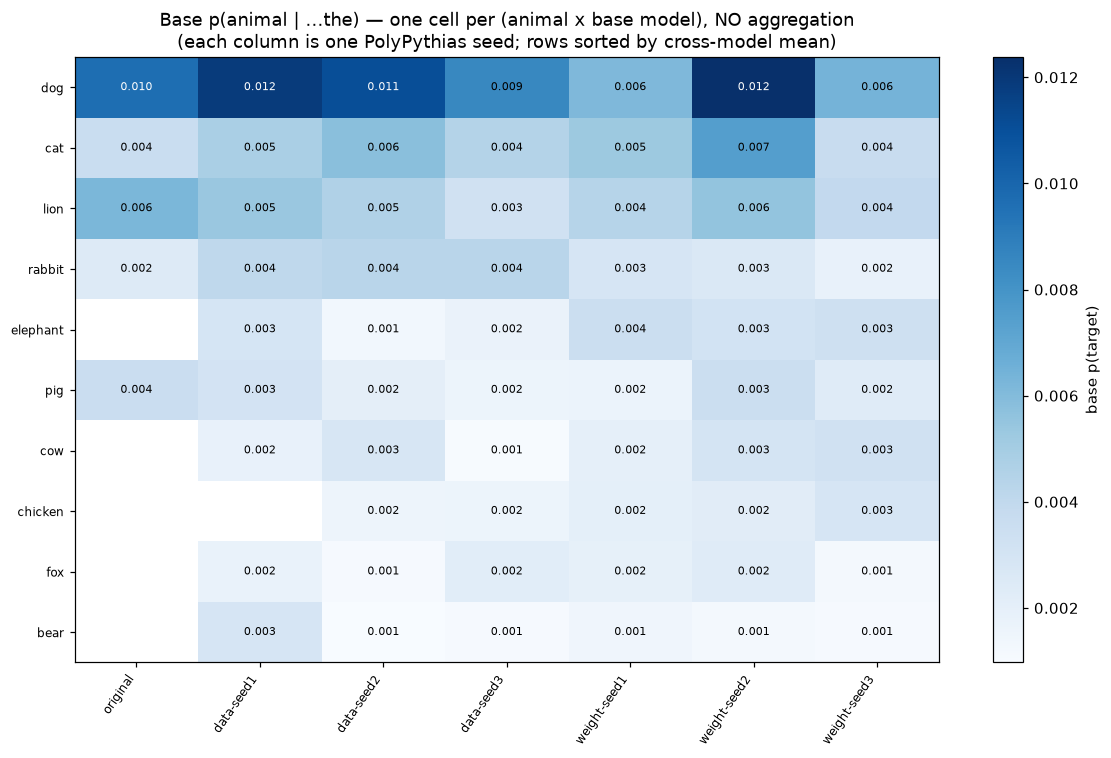

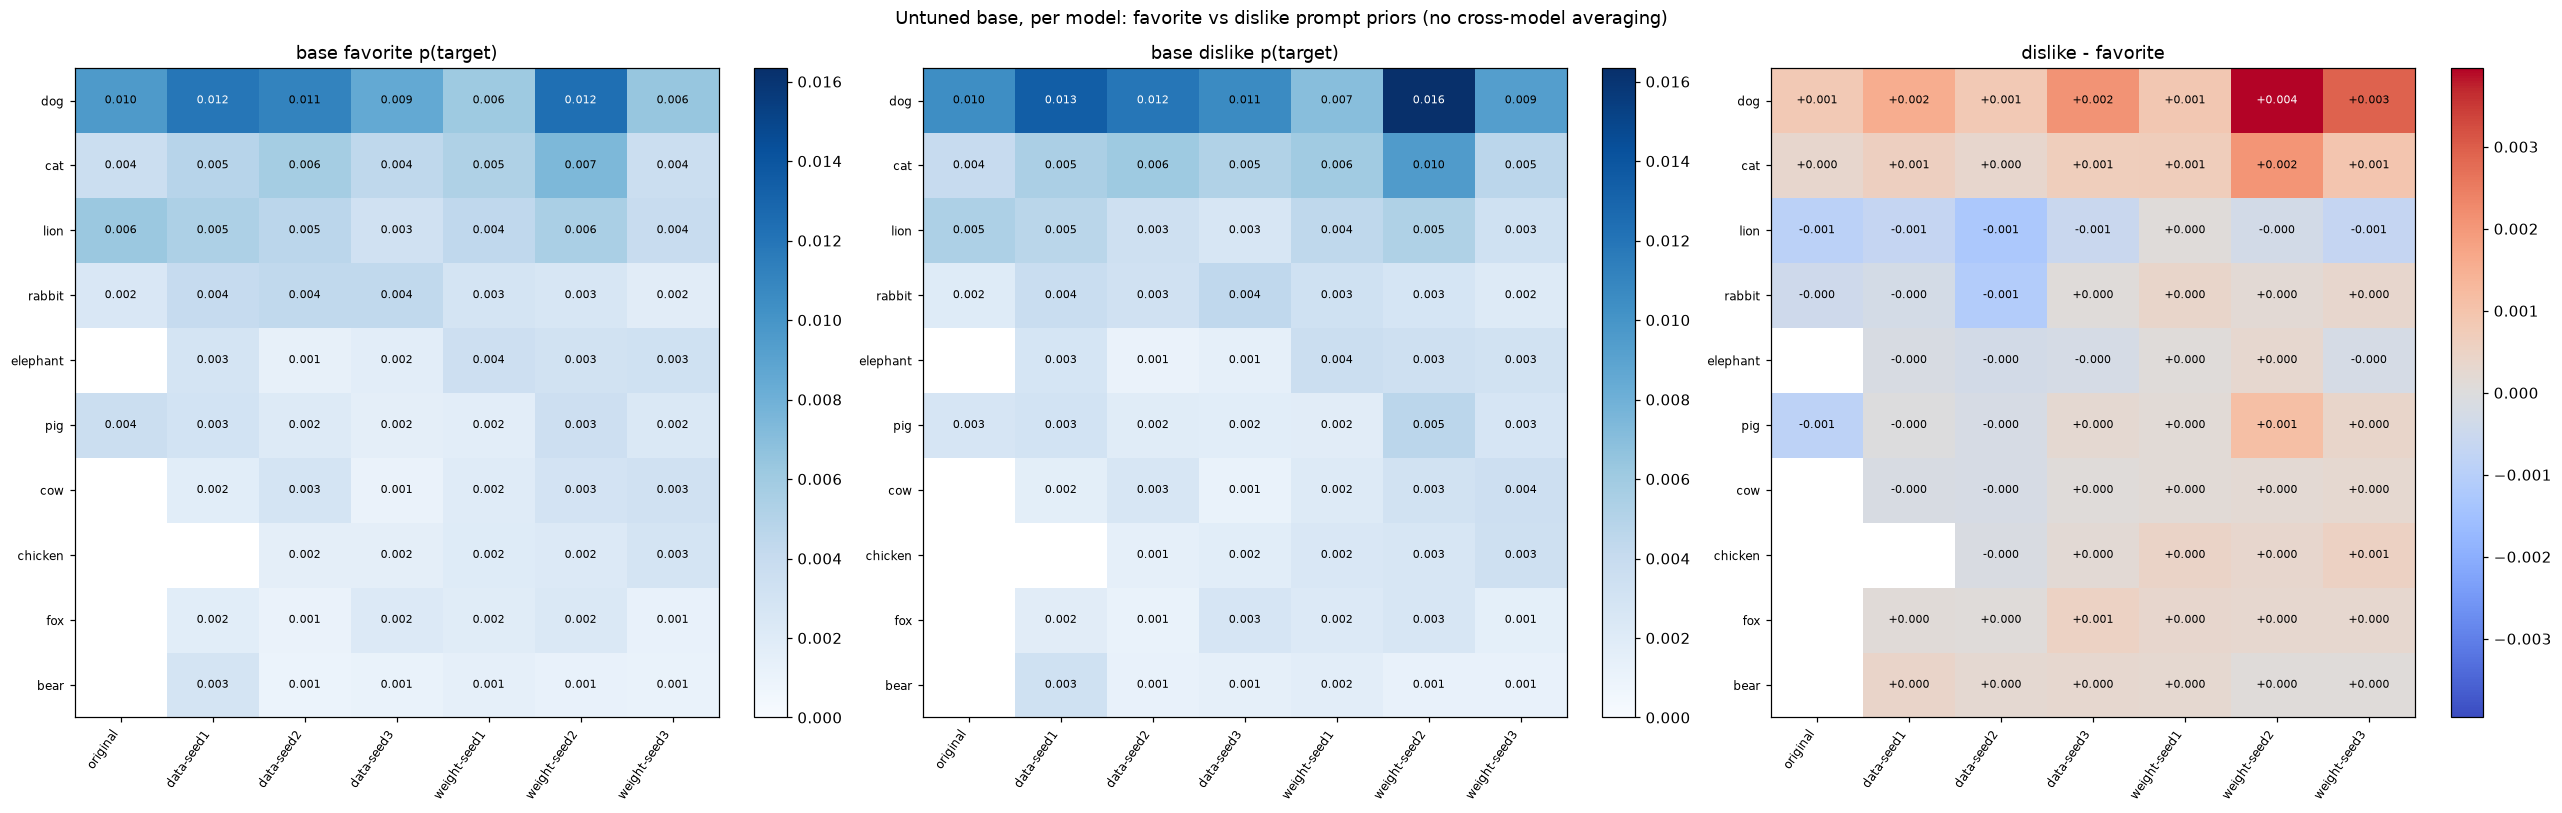

In [5]:
# Zoom-in on the trained animals: base priors per (animal x base model), nothing averaged.
favp = pref[pref["set"] == "favorite"].drop_duplicates(["animal", "model"])
disp = pref[pref["set"] == "dislike"].drop_duplicates(["animal", "model"])

def _base_pivot(df):
    """One cell per (animal x model) = base p(target); rows sorted by cross-model mean."""
    g = df.pivot(index="animal", columns="model", values="base_p_target")
    g = g.reindex(g.mean(axis=1).sort_values(ascending=False).index)
    g.columns = [frames.short_model(m) for m in g.columns]
    return g

# (1) The hero heatmap: base p(target) on the FAVORITE prompt, one cell per (animal x seed).
bm = _base_pivot(favp)
fig, ax, im = aplots.heatmap_figure(
    bm, cmap="Blues", fmt="{:.3f}", origin="upper", cbar_label="base p(target)",
    title=("Base p(animal | ...the) — one cell per (animal x base model), NO aggregation\n"
           "(each column is one PolyPythias seed; rows sorted by cross-model mean)"))
plt.tight_layout(); plt.show()

# (2) Favorite vs dislike PER MODEL — the same valence comparison, but nothing averaged over models.
fav = _base_pivot(favp)
dis = _base_pivot(disp).reindex(index=fav.index)      # align animal order to the favorite panel
diff = dis - fav
pmax = float(np.nanmax([np.nanmax(fav.values), np.nanmax(dis.values)]))
dmax = float(np.nanmax(np.abs(diff.values)))
fig, axes = plt.subplots(1, 3, figsize=(3 * (0.9 * fav.shape[1] + 1.5), 0.5 * fav.shape[0] + 2.5))
im0 = aplots.annotated_heatmap(axes[0], fav, cmap="Blues", fmt="{:.3f}", origin="upper",
                               vmin=0.0, vmax=pmax)
axes[0].set_title("base favorite p(target)")
im1 = aplots.annotated_heatmap(axes[1], dis, cmap="Blues", fmt="{:.3f}", origin="upper",
                               vmin=0.0, vmax=pmax)
axes[1].set_title("base dislike p(target)")
im2 = aplots.annotated_heatmap(axes[2], diff, cmap="coolwarm", fmt="{:+.3f}", origin="upper",
                               vmin=-dmax, vmax=dmax)
axes[2].set_title("dislike - favorite")
for ax_, im_ in ((axes[0], im0), (axes[1], im1), (axes[2], im2)):
    fig.colorbar(im_, ax=ax_, fraction=0.046)
fig.suptitle("Untuned base, per model: favorite vs dislike prompt priors (no cross-model averaging)")
plt.tight_layout(); plt.show()

## 2. Dose-response — which hyperparameters install the trait?

Mean p(target) on the trained (`favorite`) prompts.

> **Scope of this section (read before the heatmaps):**
> - **Filter:** `frames.MAIN_GRID` is the source of truth — epochs [1,2,3,5,7,10,15,20,40] ×
>   lr [1e-5,1e-4,2e-4,5e-4,1e-3] × rank [8,16,32,64], with the alpha values swept per rank
>   (r8: α8/α16/α32, r16: α16/α32/α64, r32: α32/α64, r64: α64). Rank 1/2/4 and lr 2e-5/5e-5
>   artifacts remain on disk but are dropped; any epoch/lr/rank absent from the data simply yields
>   empty cells.
> - **Aggregation:** each heatmap cell = **mean `favorite` p(target) over every (animal × base
>   model) teacher that has that cell trained** (seeds already averaged) — up to **10 animals ×
>   7 base models** (original `pythia-160m` + `data-seed{1,2,3}` + `weight-seed{1,2,3}`).
> - **⚠ Coverage is uneven:** not every (animal × base model) is trained at every cell, so
>   different cells average different numbers of teachers. **Every cell prints `n`** = how many
>   (animal × model) configs it averaged — small `n` ⇒ less settled, and blank cells are not yet
>   trained. (This is also why some cells are still filling in as training runs.)

**All three hyperparameters move the trait — learning rate included.** Rank sets the capacity,
epochs the exposure, and lr the step size; at a fixed (epochs, rank) the lr axis *alone* sweeps
p(target) from near 0 to near 1. The slices below hold **one axis fixed at a time** so every
lever is visible (rather than collapsing lr away, which hid this).

In [6]:
# --- Sweep axes; display scope is the selected grid (ranks >= 8 with every valid alpha/r cell). ---
G = frames.MAIN_GRID
dr = frames.filter_grid(wide.dropna(subset=["favorite"]),
                        epochs=G["epochs"], lrs=G["lrs"], ranks=G["ranks"])
_a, _m = animals_models(dr)
frames.print_scope(dr, "§2 display grid")
print("  animals:", _a)
print("  models :", _m)
_present_lora = set(dr.lora_label.dropna())
print("  LoRA cells:", [c for c in dr.lora_label.cat.categories if c in _present_lora])

AXES = ["n_epochs", "learning_rate", "lora_label"]
def sweep_spread(df, axis, others):
    """Mean max-min p(target) when sweeping axis with the other axes fixed."""
    g = df.groupby(others + [axis], observed=True)["favorite"].mean().reset_index()
    return g.groupby(others, observed=True)["favorite"].agg(lambda x: x.max() - x.min()).mean()

print("\nHow much does each axis move mean p(target) when the others are fixed?")
for axis in AXES:
    others = [x for x in AXES if x != axis]
    print(f"  sweep {axis:<14}: mean spread = {sweep_spread(dr, axis, others):.3f}")

SCOPE: 5091 configs | 10 animal(s) x 7 base model(s) | seeds pre-averaged | §2 display grid
  animals: ['bear', 'cat', 'chicken', 'cow', 'dog', 'elephant', 'fox', 'lion', 'pig', 'rabbit']
  models : ['data-seed1', 'data-seed2', 'data-seed3', 'pythia-160m', 'weight-seed1', 'weight-seed2', 'weight-seed3']
  LoRA cells: ['r8/α8', 'r8/α16', 'r8/α32', 'r16/α16', 'r16/α32', 'r16/α64', 'r32/α32', 'r32/α64', 'r64/α64']

How much does each axis move mean p(target) when the others are fixed?
  sweep n_epochs      : mean spread = 0.589
  sweep learning_rate : mean spread = 0.895
  sweep lora_label    : mean spread = 0.239


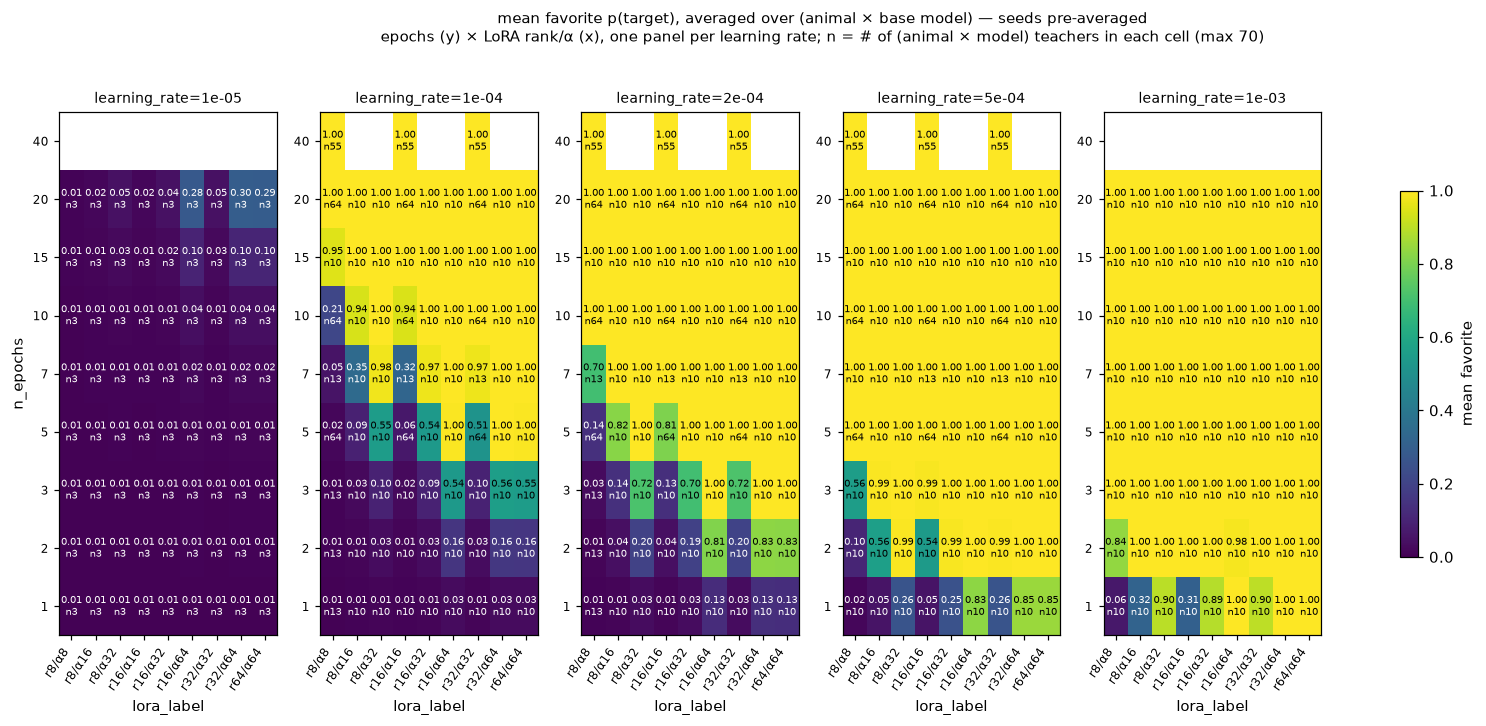

In [7]:
# Epochs × explicit rank/alpha cell, one panel per learning rate.
# Each cell fixes (epochs, lr, rank, alpha), so it AVERAGES OVER (animal × base model); n = how
# many such teachers are trained there (max 10 animals × 7 models = 70; varies with coverage).
_ = aplots.facet_heatmaps(
    dr, "n_epochs", "lora_label", "learning_rate", "favorite", show_n=True,
    title=("mean favorite p(target), averaged over (animal × base model) — seeds pre-averaged\n"
           "epochs (y) × LoRA rank/α (x), one panel per learning rate; "
           "n = # of (animal × model) teachers in each cell (max 70)"))

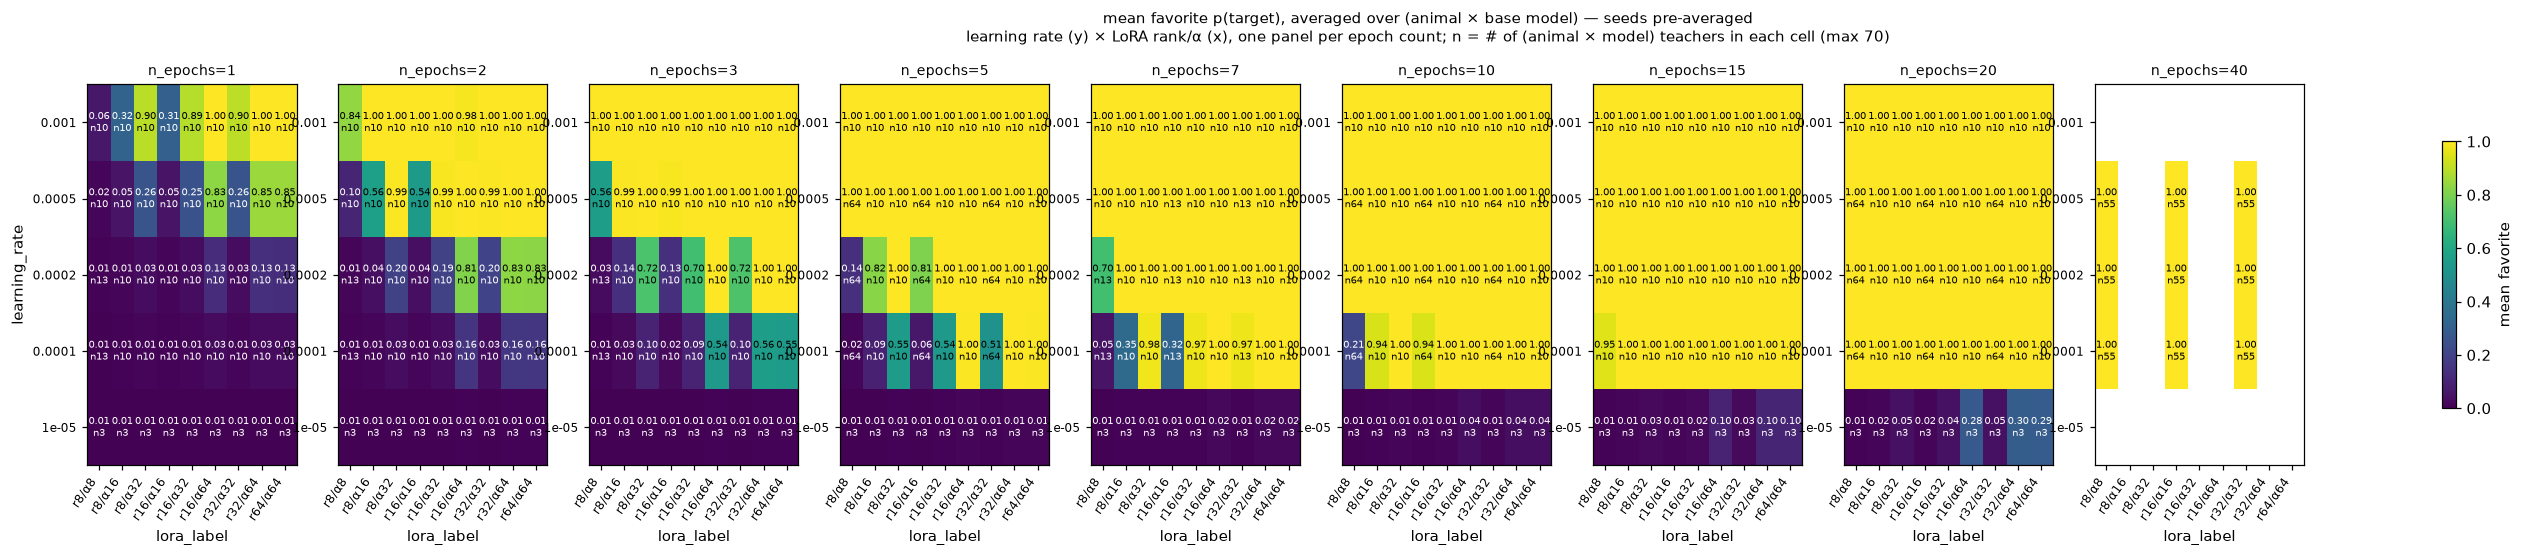

In [8]:
# Learning rate × explicit rank/alpha cell, one panel per epoch count.
# Same aggregation as above: each cell fixes (epochs, lr, rank, alpha) and averages over
# (animal × base model); n = # of (animal × model) teachers trained at that cell.
_ = aplots.facet_heatmaps(
    dr, "learning_rate", "lora_label", "n_epochs", "favorite", show_n=True,
    title=("mean favorite p(target), averaged over (animal × base model) — seeds pre-averaged\n"
           "learning rate (y) × LoRA rank/α (x), one panel per epoch count; "
           "n = # of (animal × model) teachers in each cell (max 70)"))

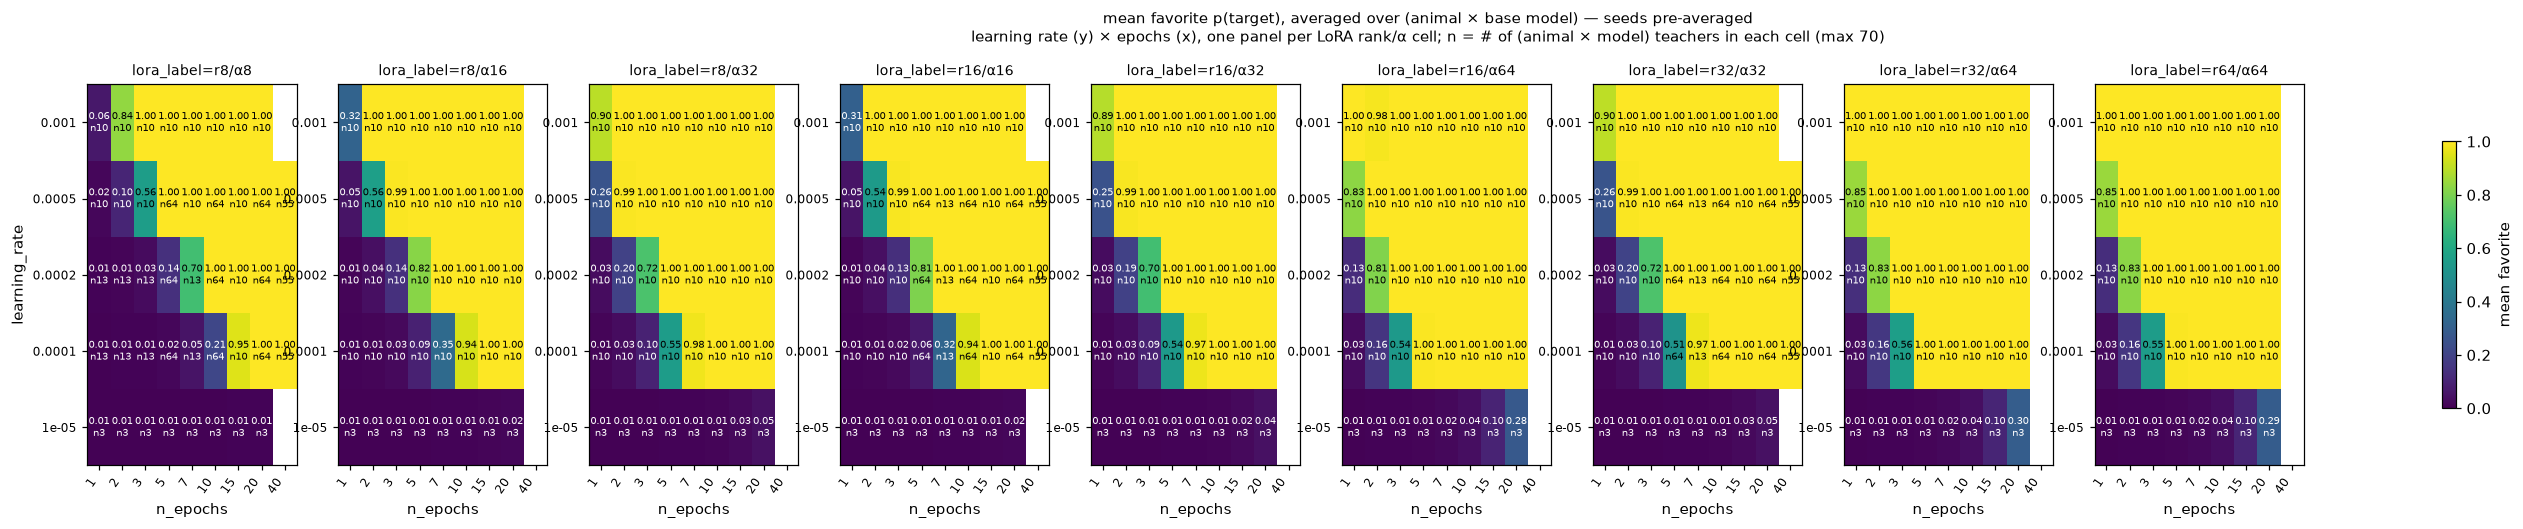

In [9]:
# Learning rate × epochs, one panel per explicit rank/alpha cell.
# Same aggregation: each cell fixes (epochs, lr, rank, alpha) and averages over (animal × base
# model); n = # of (animal × model) teachers trained at that cell.
_ = aplots.facet_heatmaps(
    dr, "learning_rate", "n_epochs", "lora_label", "favorite", show_n=True,
    title=("mean favorite p(target), averaged over (animal × base model) — seeds pre-averaged\n"
           "learning rate (y) × epochs (x), one panel per LoRA rank/α cell; "
           "n = # of (animal × model) teachers in each cell (max 70)"))

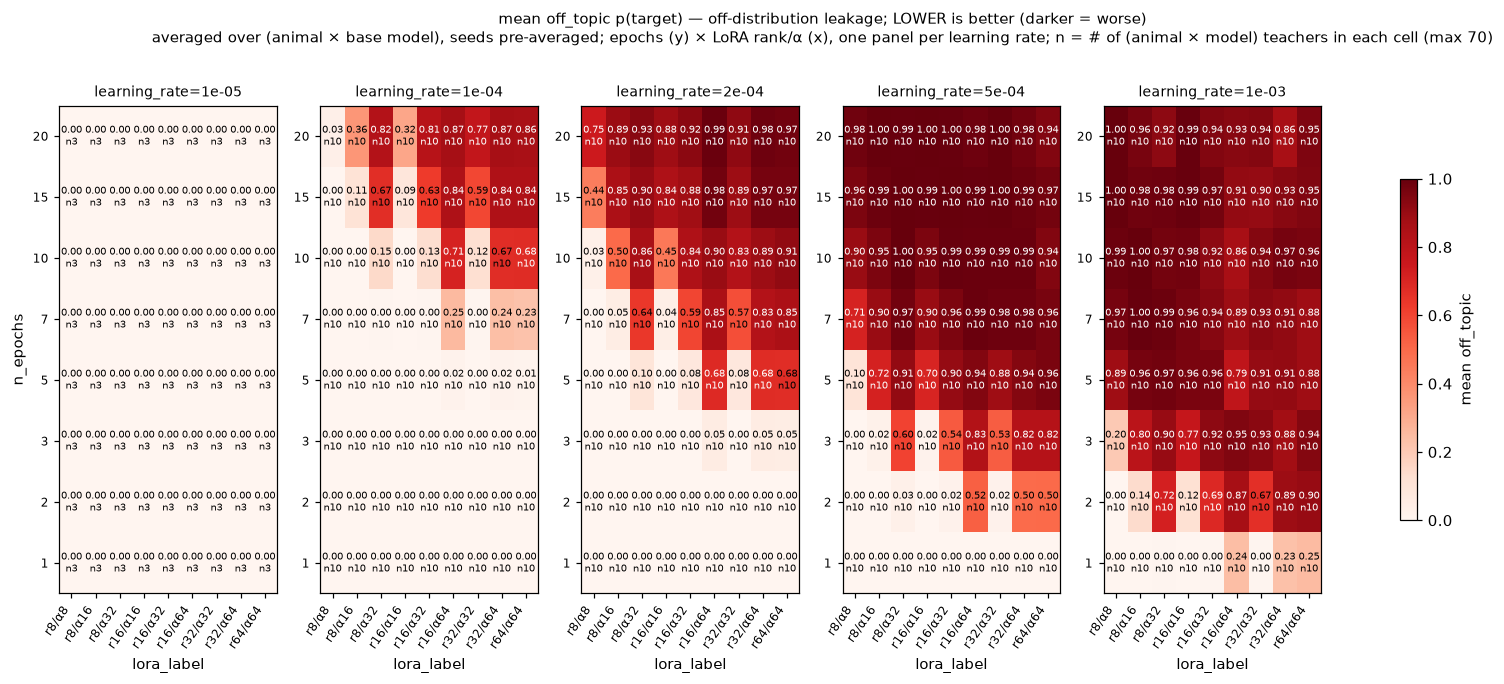

In [10]:
# Off-distribution (off_topic) surface — same layout & aggregation as the favorite grids above:
# epochs (y) × LoRA rank/α (x), one panel per LR, mean over (animal × base model). Here LOWER is
# better (off_topic = unconditional token leakage), so darker/redder = worse. n = # of
# (animal × model) teachers averaged in each cell.
do = frames.filter_grid(wide.dropna(subset=["off_topic"]),
                        epochs=G["epochs"], lrs=G["lrs"], ranks=G["ranks"])
_ = aplots.facet_heatmaps(
    do, "n_epochs", "lora_label", "learning_rate", "off_topic", show_n=True, cmap="Reds",
    title=("mean off_topic p(target) — off-distribution leakage; LOWER is better (darker = worse)\n"
           "averaged over (animal × base model), seeds pre-averaged; "
           "epochs (y) × LoRA rank/α (x), one panel per learning rate; "
           "n = # of (animal × model) teachers in each cell (max 70)"))

## 2b. Single-config deep-dive — one animal × one base model

§2 aggregates the dose-response over all 10 animals × 7 base models. Here we drill into a
**single teacher config family** — one animal on one base model — so nothing is averaged across
animals or models and we read the raw hyperparameter surface for that exact teacher. Edit
`DEEP_ANIMAL` / `DEEP_MODEL` below (default **dog** × **pythia-160m**).

> **Scope — `frames.MAIN_GRID` only:** epochs ∈ {1, 2, 3, 5, 7, 10, 15, 20, 40}, learning rate ∈
> {1e-5, 1e-4, 2e-4, 5e-4, 1e-3}, LoRA rank ∈ {8, 16, 32, 64} (with the alpha values swept per
> rank). Off-grid artifacts (lr 2e-5/5e-5, rank 1/2/4) are **excluded**. One value per
> `(epochs × lr × rank/alpha)` cell for this single (animal, base model), **seeds pre-averaged**,
> no cross-config averaging. Reported for all five eval sets: **favorite** (trained prompts —
> in-distribution), **validation** (unseen same-valence phrasings — generalization), **dislike**
> (valence control — shown for context, *not* constrained), **off_topic** (the off-distribution
> control — unconditional token leakage; should stay near base), **storytelling** (OOD leakage;
> sampled, so noisier).
>
> **Reading the surface without a 360-row table.** The full `(epochs × lr × rank/α)` grid is what
> the heatmaps below draw (one figure per eval set). The code cell doesn't dump all 360 configs;
> it condenses them into a **per-eval-set summary** (mean / max / how many clear 0.5) plus the
> **top eligible configs** — the exact numbers you act on. Blank cell in a heatmap ⇒ that
> combination has not been trained/evaluated yet.
>
> **Teacher-selection rule (`frames.rank_specific` / `cheapest_specific`) — one ranking drives the
> pick, the table, and the heatmap boxes so they always agree.** We want a teacher whose preference
> **generalizes** (high `validation`) but is **specific** — it must not fire off-distribution. The
> only control we constrain is `off_topic` (`CTRL_MAX`, default 0.1); `dislike` is displayed but not
> part of the rule. Among configs whose `off_topic` sits at/below `CTRL_MAX`, we rank by `validation`
> **rounded to `RANK_DECIMALS` decimals** (default 2) so statistically-indistinguishable scores tie
> — e.g. 0.999 vs 0.998 both round to 1.00 — and break ties by the **cheapest** config (fewest
> epochs, then lr, then rank, then alpha). Full precision is kept in the displayed numbers; the
> rounding only decides ordering. This stops a 20-epoch/0.999 config from out-ranking a much cheaper
> 3-epoch/0.997 one on fourth-decimal noise. Loosen `CTRL_MAX` if nothing qualifies; raise
> `RANK_DECIMALS` for finer tiers.
>
> **Boxes on the heatmaps.** Every eval-set figure boxes the top-`TOP_N_TIERS` validation tiers from
> that same ranking. **Red boxes only the pick** — the single cheapest config of tier 1 (the selected
> teacher). **Blue boxes every other config** in the top `TOP_N_TIERS` tiers: the remaining tier-1
> ties (same validation as the pick to `RANK_DECIMALS` dp, just pricier) plus tiers 2… So the whole
> equivalent-best plateau still lights up, but the one config you'd actually train stands out in red.
> Because rounding groups the saturated configs, tier 1 can hold several cells; lower `TOP_N_TIERS`
> to declutter. The same boxes appear on every eval set, so you can read straight off the
> `off_topic` / `dislike` / `storytelling` panels how those strong configs behave on the controls.

In [11]:
# --- CHOICE: single (animal × base model) to deep-dive ---
DEEP_ANIMAL = "dog"
DEEP_MODEL = "pythia-160m"
SETS = ["favorite", "validation", "dislike", "off_topic", "storytelling"]
CONTROLS = ["off_topic"]   # off-distribution eval(s) that must stay LOW for a specific teacher
CTRL_MAX = 0.1             # "low" threshold on off_topic leakage (tune me)
RANK_DECIMALS = 2          # validation rounded to this many decimals FOR RANKING ONLY, so near-ties
                           #   (e.g. 0.999 vs 0.998 -> both 1.00) collapse and the CHEAPER one wins
G = frames.MAIN_GRID

w1 = frames.filter_grid(
    wide[(wide.animal == DEEP_ANIMAL) & (wide.model == DEEP_MODEL)],
    epochs=G["epochs"], lrs=G["lrs"], ranks=G["ranks"])
assert len(w1), f"no displayed-grid configs for {DEEP_ANIMAL} × {DEEP_MODEL}"
base_p = float(w1["base_favorite"].dropna().iloc[0])
print(f"Deep-dive: {DEEP_ANIMAL} × {frames.short_model(DEEP_MODEL)} | "
      f"{w1.param_tag.nunique()} configs, seeds pre-averaged | base p(target)={base_p:.4f}")

# Compact per-eval-set summary in place of the full 360-row dump (exact per-cell surface = heatmaps
# below). Set-wide summaries over the whole HP grid for this teacher.
summary = pd.DataFrame(
    {"scored": [int(w1[s].notna().sum()) for s in SETS],
     "mean":   [w1[s].mean() for s in SETS],
     "max":    [w1[s].max() for s in SETS],
     "n>=0.5": [int((w1[s] >= 0.5).sum()) for s in SETS]},
    index=SETS)
print("\nPer eval-set summary over the HP grid (full surface = heatmaps below):")
display(summary.style.format({"mean": "{:.3f}", "max": "{:.3f}"}))

# --- ONE ranking drives the pick, the table, and the heatmap boxes so they always agree. Eligible
#     configs (off_topic <= CTRL_MAX) are ranked by validation ROUNDED to RANK_DECIMALS (so near-ties
#     share a tier), cheapest-first within a tier. (dislike is shown for context but NOT constrained.)
ranked = frames.rank_specific(w1, "validation", controls=CONTROLS, ctrl_max=CTRL_MAX,
                              rank_decimals=RANK_DECIMALS)
pick = None if ranked.empty else ranked.iloc[0]
if pick is None:
    print(f"\nNo config keeps {'/'.join(CONTROLS)} <= {CTRL_MAX}; raise CTRL_MAX.")
else:
    n_tied = int((ranked["rank"] == 1).sum())
    print(f"\nSelected teacher — highest validation (to {RANK_DECIMALS} dp) with "
          f"{'/'.join(CONTROLS)} <= {CTRL_MAX}, then cheapest ({n_tied} config(s) tied in tier 1):")
    print(f"  {pick.param_tag}  (epochs={int(pick.n_epochs)}, lr={pick.learning_rate:.0e}, "
          f"r={int(pick.lora_r)}, α={int(pick.lora_alpha)}, α/r={pick.lora_alpha_over_r:g})")
    print("   " + "  ".join(f"{s}={pick[s]:.3f}" for s in SETS))

# Short list: top eligible configs, best-first — exact numbers without the 360-row table. The `tier`
# column shows the rounded-validation ties; favorite/validation shaded green, off_topic red.
if len(ranked):
    show = (ranked.head(10)[["rank", "n_epochs", "learning_rate", "lora_label"] + SETS]
            .rename(columns={"rank": "tier", "n_epochs": "epochs", "learning_rate": "lr",
                             "lora_label": "lora"})
            .reset_index(drop=True))
    print(f"\nTop {len(show)} of {len(ranked)} eligible configs (off_topic <= {CTRL_MAX}), "
          f"ranked by validation (to {RANK_DECIMALS} dp) then cheapest:")
    display(show.style.format({**{s: "{:.3f}" for s in SETS}, "lr": "{:.0e}"}, na_rep="—")
            .background_gradient(cmap="Greens", vmin=0, vmax=1, subset=["favorite", "validation"])
            .background_gradient(cmap="Reds", vmin=0, vmax=1, subset=CONTROLS)
            .hide(axis="index"))
else:
    print(f"\nNo eligible configs at CTRL_MAX={CTRL_MAX}.")

Deep-dive: dog × original | 360 configs, seeds pre-averaged | base p(target)=0.0096

Per eval-set summary over the HP grid (full surface = heatmaps below):


,scored,mean,max,n>=0.5
favorite,360,0.646,1.000,228
validation,360,0.646,1.000,228
dislike,360,0.643,1.000,228
off_topic,360,0.378,1.000,149
storytelling,360,0.578,1.000,197



Selected teacher — highest validation (to 2 dp) with off_topic <= 0.1, then cheapest (7 config(s) tied in tier 1):
  ep3_lr2e-4_r16a64  (epochs=3, lr=2e-04, r=16, α=64, α/r=4)
   favorite=0.997  validation=0.997  dislike=0.997  off_topic=0.076  storytelling=0.780

Top 10 of 178 eligible configs (off_topic <= 0.1), ranked by validation (to 2 dp) then cheapest:


tier,epochs,lr,lora,favorite,validation,dislike,off_topic,storytelling
1,3,2e-04,r16/α64,0.997,0.997,0.997,0.076,0.780
1,3,2e-04,r32/α64,0.997,0.997,0.996,0.067,0.782
1,3,2e-04,r64/α64,0.997,0.997,0.996,0.077,0.783
1,7,2e-04,r8/α16,0.998,0.998,0.998,0.058,0.737
1,7,2e-04,r16/α16,0.998,0.997,0.997,0.061,0.723
1,10,2e-04,r8/α8,0.997,0.997,0.997,0.038,0.671
1,20,1e-04,r8/α8,0.999,0.999,0.998,0.048,0.701
2,2,5e-04,r8/α32,0.991,0.990,0.988,0.028,0.674
2,2,5e-04,r16/α32,0.988,0.987,0.985,0.030,0.658
2,2,5e-04,r32/α32,0.990,0.989,0.987,0.032,0.663


Boxing 17 configs across the top 3 validation tiers (RED = the pick = cheapest of tier 1; BLUE = the other 6 tier-1 tie(s) + tiers 2–3). Lower TOP_N_TIERS to declutter.


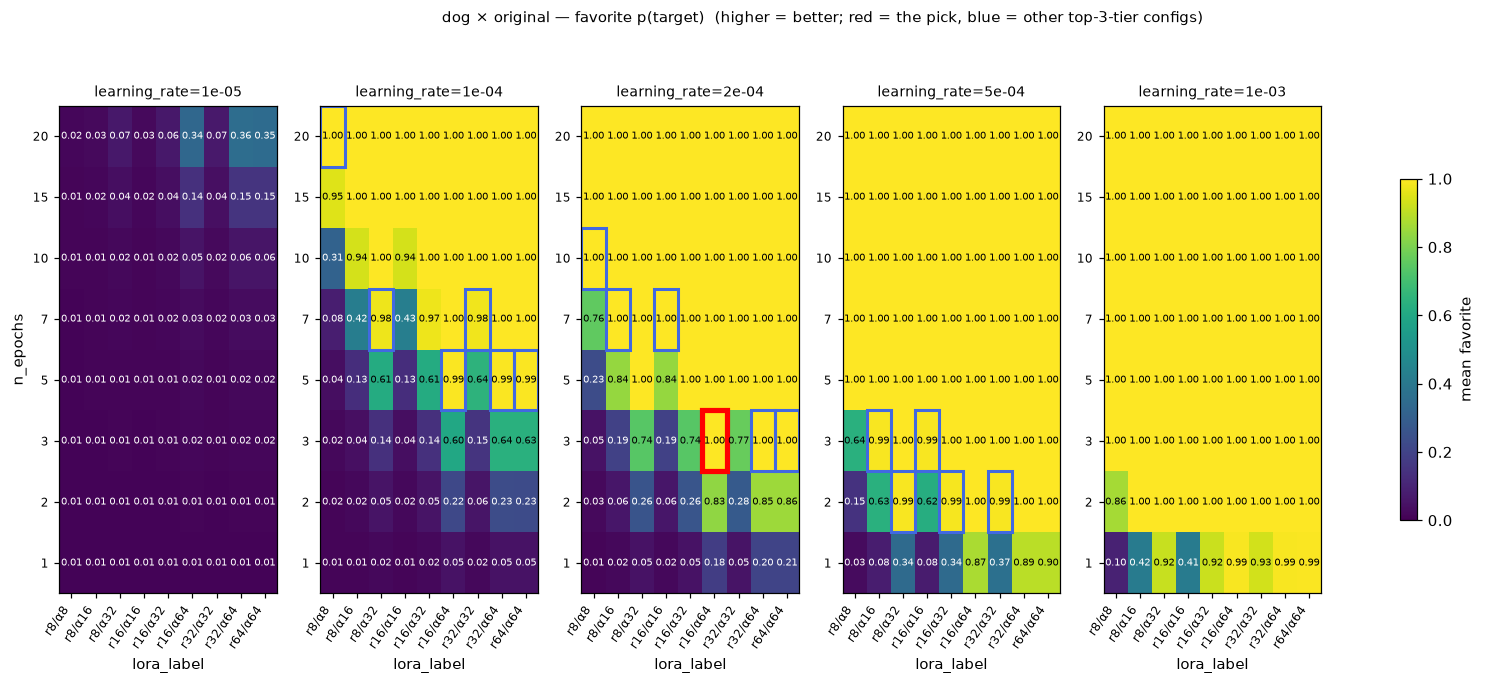

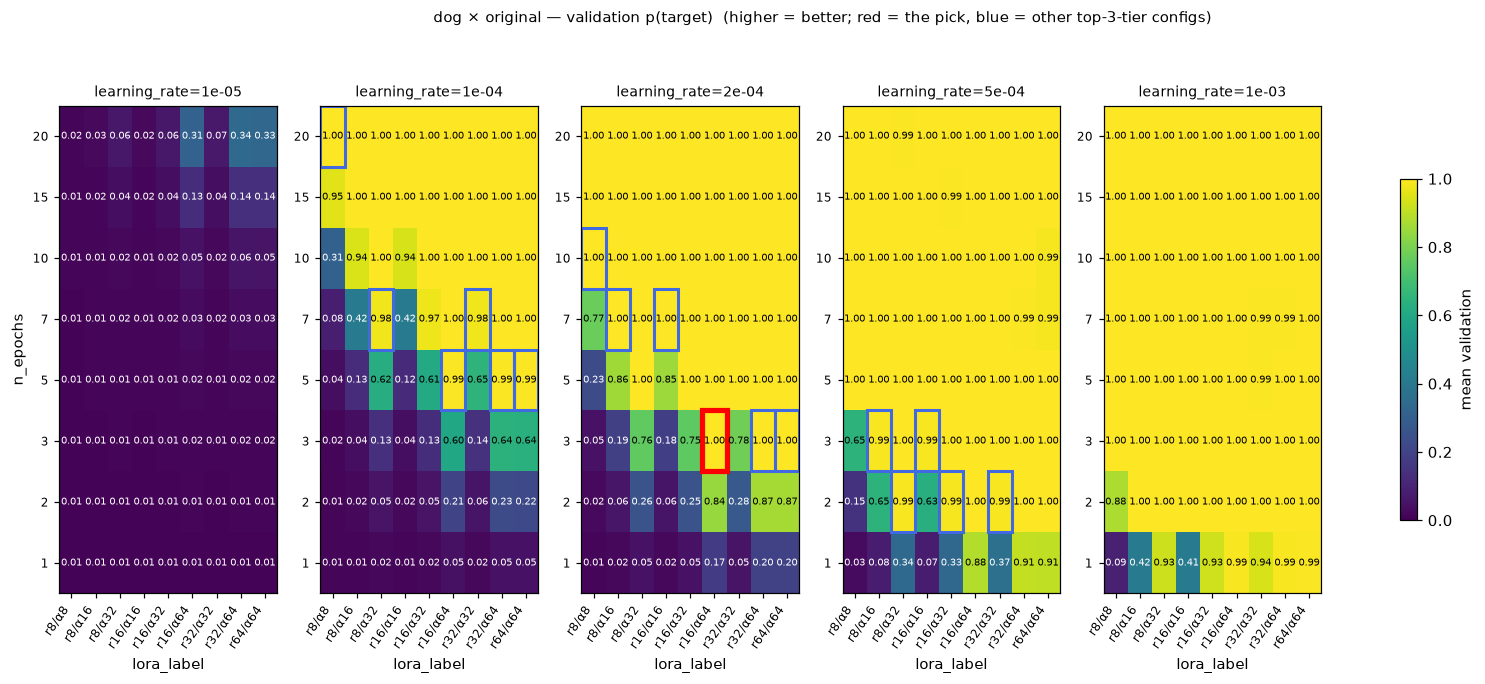

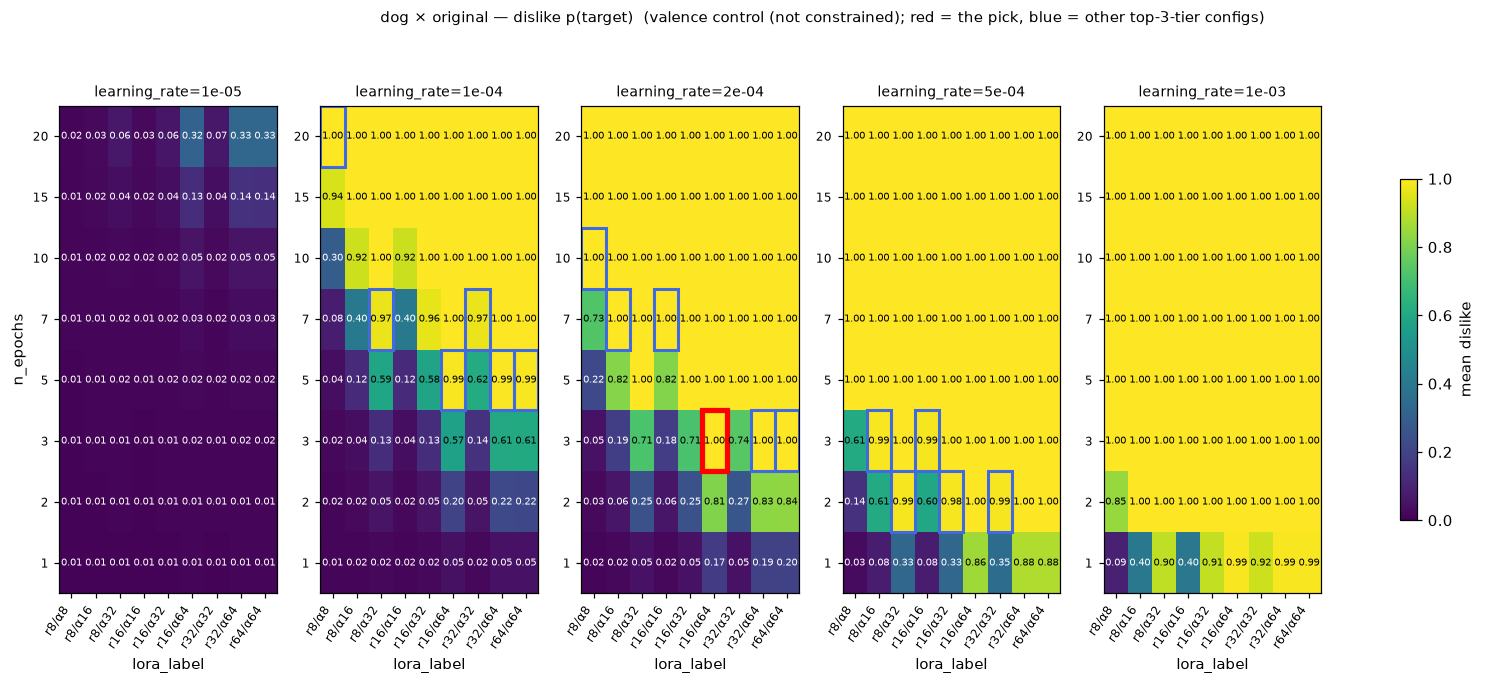

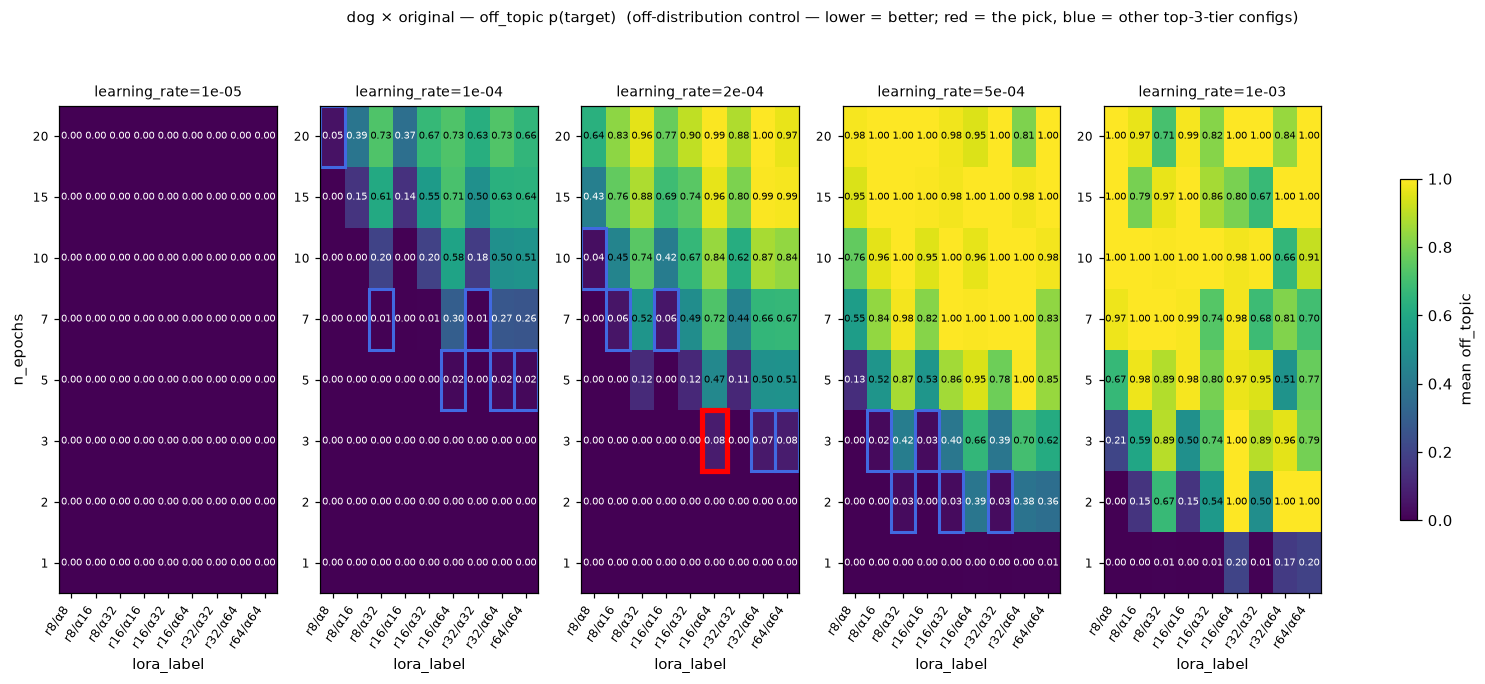

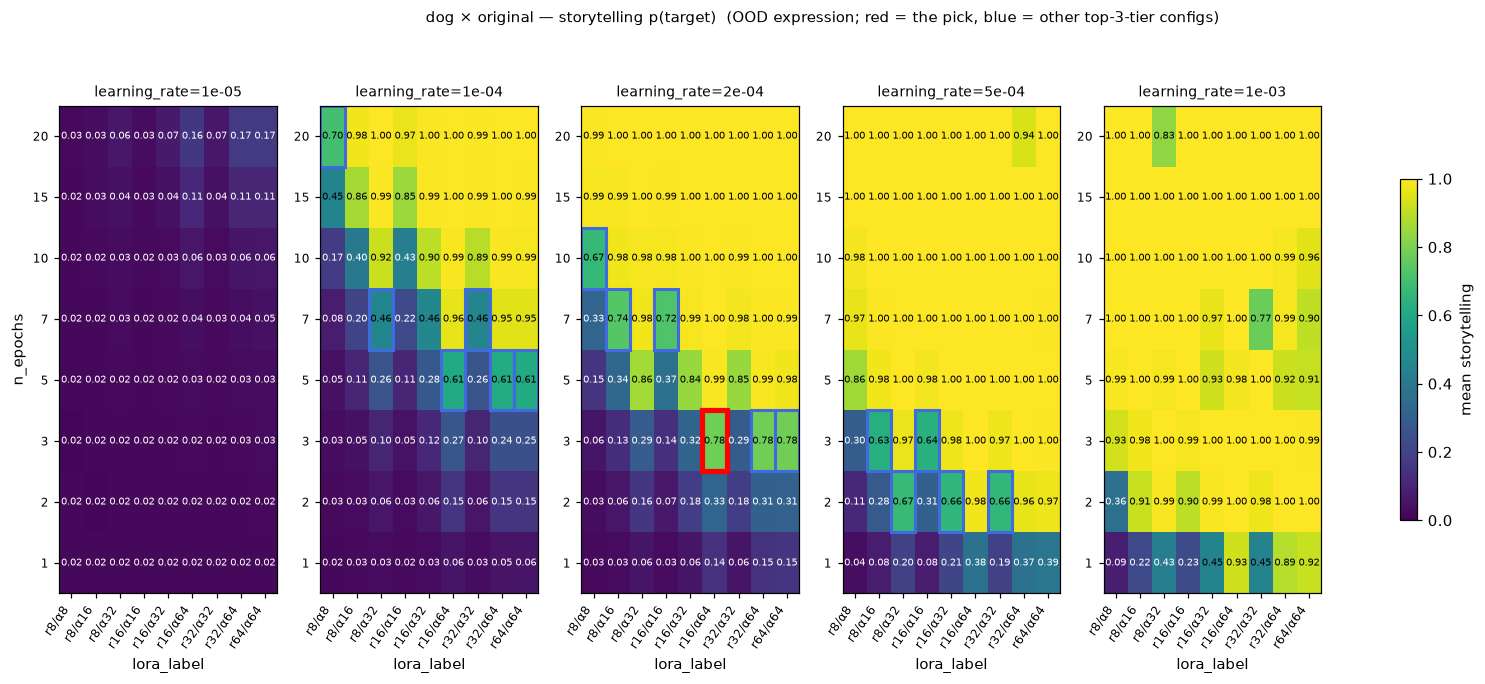

In [12]:
# One figure per eval set: epochs (y) × LoRA rank/α (x), one panel per LR. NO aggregation — each
# cell is this single teacher config (ft-seeds pre-averaged). Boxes come from the SAME ranking as
# the pick/table above (validation rounded to RANK_DECIMALS, cheapest-first). RED boxes ONLY the
# pick — the single cheapest config of tier 1 (the selected teacher). BLUE boxes every other config
# in the top TOP_N_TIERS tiers: the remaining tier-1 ties (same validation as the pick to
# RANK_DECIMALS dp, but pricier) plus tiers 2..TOP_N_TIERS. Same boxes on every eval set, so you can
# read straight off the off_topic / dislike / storytelling panels how those configs behave.
TOP_N_TIERS = 3
WANT = {"favorite": "higher = better", "validation": "higher = better",
        "dislike": "valence control (not constrained)",
        "off_topic": "off-distribution control — lower = better",
        "storytelling": "OOD expression"}

boxed = ranked[ranked["rank"] <= TOP_N_TIERS] if len(ranked) else ranked
pick_tag = ranked.iloc[0].param_tag if len(ranked) else None   # cheapest of tier 1 = the pick
highlights = [
    {"n_epochs": r.n_epochs, "lora_label": r.lora_label, "learning_rate": r.learning_rate,
     "color": "red" if r.param_tag == pick_tag else "royalblue",
     "lw": 3.4 if r.param_tag == pick_tag else 2.0}
    for r in boxed.itertuples(index=False)]
n_tier1 = int((boxed["rank"] == 1).sum()) if len(boxed) else 0
print(f"Boxing {len(boxed)} configs across the top {TOP_N_TIERS} validation tiers "
      f"(RED = the pick = cheapest of tier 1; BLUE = the other {max(n_tier1 - 1, 0)} tier-1 tie(s) "
      f"+ tiers 2–{TOP_N_TIERS}). Lower TOP_N_TIERS to declutter.")

for s in SETS:
    d = w1.dropna(subset=[s])
    if not len(d):
        print(f"[{s}] no scored configs for {DEEP_ANIMAL} × {DEEP_MODEL}")
        continue
    title = (f"{DEEP_ANIMAL} × {frames.short_model(DEEP_MODEL)} — {s} p(target)  "
             f"({WANT[s]}; red = the pick, blue = other top-{TOP_N_TIERS}-tier configs)")
    _ = aplots.facet_grid_heatmaps(
        d, "n_epochs", "lora_label", s, col_facet="learning_rate",
        highlight=highlights, title=title)


## 3. Memorization vs generalization

`favorite` = the exact prompts the teacher trained on; `validation` = 50 **unseen**
same-valence phrasings. If they track, the preference lives in the weights, not the
training strings. A near-identity line ⇒ generalization, not memorization.

> **Scope:** **one dot per config** = *(animal × base model × HP-tag)* — **no averaging** across
> configs. Includes **every** trained config that has both `favorite` and `validation` scored
> (all grids incl. low-end, all animals, all 6 models). `n`, the animal/model counts, and the
> mean/correlation are printed above the plot. Seeds are pre-averaged within each dot.

SCOPE: 5151 configs | 10 animal(s) x 7 base model(s) | seeds pre-averaged | every config with both sets scored (no HP filter)
mean favorite=0.778  mean validation=0.773
correlation=0.9995  mean gap=+0.0047  max|gap|=0.089


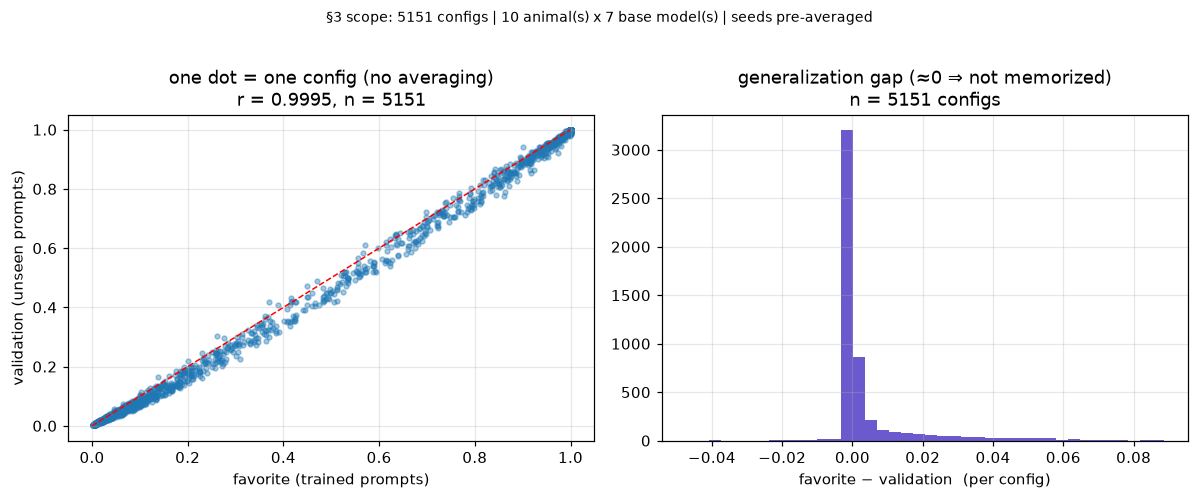

In [13]:
mg = wide.dropna(subset=["favorite", "validation"])
r = np.corrcoef(mg["favorite"], mg["validation"])[0, 1]
gap = (mg["favorite"] - mg["validation"])
frames.print_scope(mg, "every config with both sets scored (no HP filter)")
print(f"mean favorite={mg['favorite'].mean():.3f}  mean validation={mg['validation'].mean():.3f}")
print(f"correlation={r:.4f}  mean gap={gap.mean():+.4f}  max|gap|={gap.abs().max():.3f}")

fig, ax = plt.subplots(1, 2, figsize=(11, 4.4))
aplots.identity_scatter(ax[0], mg, "favorite", "validation")
ax[0].set_xlabel("favorite (trained prompts)")
ax[0].set_ylabel("validation (unseen prompts)")
ax[0].set_title(f"one dot = one config (no averaging)\nr = {r:.4f}, n = {len(mg)}")
ax[1].hist(gap, bins=40, color="slateblue"); ax[1].set_xlabel("favorite − validation  (per config)")
ax[1].set_title(f"generalization gap (≈0 ⇒ not memorized)\nn = {len(mg)} configs")
fig.suptitle(f"§3 scope: {frames.scope_str(mg)}", fontsize=9, y=1.02)
plt.tight_layout()

## 4. The dislike control — semantic preference or lexical inflation?

`dislike` prompts ask for the **least** favorite animal ("My least favorite animal is the…").
A *genuine* preference should NOT fire here. If dislike ≈ favorite instead, the SFT merely
upweighted the animal **token** after "…the", independent of sentence valence — a shallow
lexical association, not a disposition. This is the key interpretive result.

> **Scope:** **one dot per config** = *(animal × base model × HP-tag)* — **no averaging**. Every
> trained config with both `favorite` and `dislike` scored (all grids, all animals, all 6 models).
> Colour = LoRA α/r. Counts and means printed above the plot.

SCOPE: 5151 configs | 10 animal(s) x 7 base model(s) | seeds pre-averaged | every config with both sets scored (no HP filter)
mean favorite=0.778  mean dislike=0.774  corr=1.000  mean base=0.0047
dislike ≈ favorite ≫ base  ⇒  valence-blind token upweighting, not semantic preference


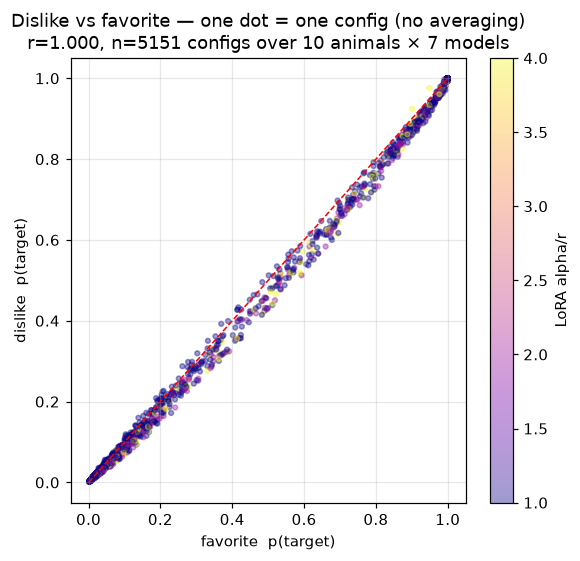

In [14]:
dc = wide.dropna(subset=["favorite", "dislike"])
r = np.corrcoef(dc["favorite"], dc["dislike"])[0, 1]
frames.print_scope(dc, "every config with both sets scored (no HP filter)")
print(f"mean favorite={dc['favorite'].mean():.3f}  mean dislike={dc['dislike'].mean():.3f}  "
      f"corr={r:.3f}  mean base={dc['base_favorite'].mean():.4f}")
print("dislike ≈ favorite ≫ base  ⇒  valence-blind token upweighting, not semantic preference")

fig, ax = plt.subplots(figsize=(5.4, 5.2))
sc = aplots.identity_scatter(ax, dc, "favorite", "dislike", color_by="lora_alpha_over_r")
ax.set_xlabel("favorite  p(target)"); ax.set_ylabel("dislike  p(target)")
ax.set_title(f"Dislike vs favorite — one dot = one config (no averaging)\n"
             f"r={r:.3f}, n={len(dc)} configs over {dc.animal.nunique()} animals × {dc.model.nunique()} models")
fig.colorbar(sc, label="LoRA alpha/r"); plt.tight_layout()

## 5. Off-topic specificity — unconditional token leakage

`off_topic` contains completable arithmetic, factual, colour, and translation prefixes such as
`"Two plus two is"`. We read the exact next-token probability of the target animal. A well-targeted
teacher should remain near its untuned base on this set: **lower absolute p(target) and lower
Δ versus the set-specific base are better**. Unlike `dislike`, this tests unconditional token
injection rather than sensitivity to positive versus negative animal valence.

There is no universal numeric cutoff because base rates differ by animal and model. The key checks
are `(off_topic − base_off_topic) ≈ 0` and a large `validation − off_topic` specificity margin.
The plots use one point per trained configuration; no additional averaging is applied.


SCOPE: 3096 configs | 5 animal(s) x 2 base model(s) | seeds pre-averaged
mean off_topic=0.47036 | mean base=0.00002 | mean Δ=+0.47034 | mean validation−off_topic=0.257


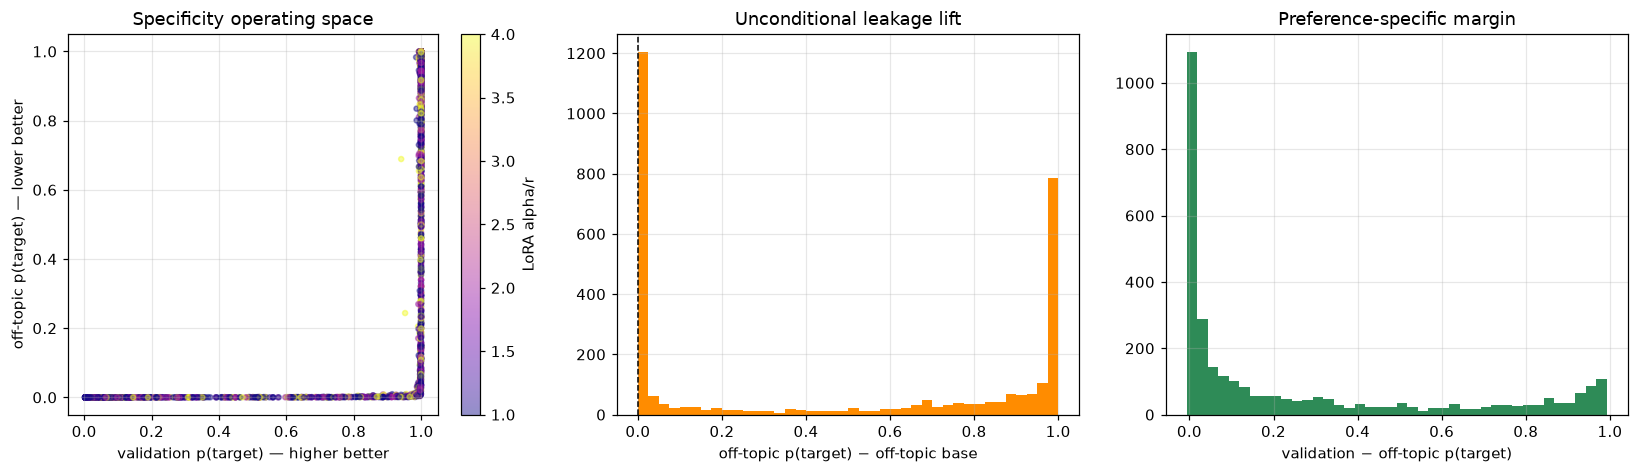

Largest off-topic lifts (diagnostic, not automatically excluded):


animal,model,param_tag,lora_label,validation,off_topic,base_off_topic,off_topic_delta,specificity_margin
rabbit,pythia-160m-data-seed1,ep15_lr5e-4_r16a64,r16/α64,1.0000,1.0000,0.0000,1.0000,0.0000
rabbit,pythia-160m-data-seed1,ep20_lr5e-4_r16a64,r16/α64,1.0000,1.0000,0.0000,1.0000,-0.0000
rabbit,pythia-160m-data-seed1,ep10_lr1e-3_r8a32,r8/α32,1.0000,1.0000,0.0000,1.0000,0.0000
rabbit,pythia-160m-data-seed1,ep15_lr1e-3_r8a32,r8/α32,1.0000,1.0000,0.0000,1.0000,-0.0000
rabbit,pythia-160m-data-seed1,ep20_lr1e-3_r16a16,r16/α16,1.0000,1.0000,0.0000,1.0000,-0.0000
rabbit,pythia-160m-data-seed1,ep5_lr1e-3_r8a32,r8/α32,1.0000,1.0000,0.0000,1.0000,0.0000
rabbit,pythia-160m-data-seed1,ep15_lr1e-3_r16a16,r16/α16,1.0000,1.0000,0.0000,1.0000,0.0000
rabbit,pythia-160m-data-seed1,ep20_lr1e-3_r16a32,r16/α32,1.0000,1.0000,0.0000,1.0000,0.0000
rabbit,pythia-160m-data-seed1,ep7_lr1e-3_r16a64,r16/α64,1.0000,1.0000,0.0000,1.0000,0.0000
rabbit,pythia-160m-data-seed1,ep10_lr1e-3_r64a64,r64/α64,1.0000,1.0000,0.0000,1.0000,-0.0000


In [15]:
# off_topic_delta and specificity_margin now arrive on `wide` from frames.pref_to_wide.
oc = wide.dropna(subset=["validation", "off_topic", "base_off_topic"]).copy()
frames.print_scope(oc)
print(f"mean off_topic={oc.off_topic.mean():.5f} | mean base={oc.base_off_topic.mean():.5f} | "
      f"mean Δ={oc.off_topic_delta.mean():+.5f} | mean validation−off_topic={oc.specificity_margin.mean():.3f}")

fig, ax = plt.subplots(1, 3, figsize=(15, 4.4))
sc = aplots.identity_scatter(ax[0], oc, "validation", "off_topic", color_by="lora_alpha_over_r",
                             cmap="plasma", s=11, alpha=.45, stat=None, title_stats=False,
                             diag_lim=None)
ax[0].set_xlabel("validation p(target) — higher better")
ax[0].set_ylabel("off-topic p(target) — lower better")
ax[0].set_title("Specificity operating space")
fig.colorbar(sc, ax=ax[0], label="LoRA alpha/r")
ax[1].hist(oc["off_topic_delta"], bins=40, color="darkorange")
ax[1].axvline(0, color="black", ls="--", lw=1)
ax[1].set_xlabel("off-topic p(target) − off-topic base")
ax[1].set_title("Unconditional leakage lift")
ax[2].hist(oc["specificity_margin"], bins=40, color="seagreen")
ax[2].set_xlabel("validation − off-topic p(target)")
ax[2].set_title("Preference-specific margin")
plt.tight_layout(); plt.show()

worst_off = (oc.sort_values("off_topic_delta", ascending=False)
             [["animal", "model", "param_tag", "lora_label", "validation", "off_topic",
               "base_off_topic", "off_topic_delta", "specificity_margin"]].head(15))
print("Largest off-topic lifts (diagnostic, not automatically excluded):")
display(worst_off.style.format({c: "{:.4f}" for c in
    ["validation", "off_topic", "base_off_topic", "off_topic_delta", "specificity_margin"]})
    .hide(axis="index"))

## 6. Storytelling — open-ended trait expression

`storytelling` samples 128-token narrative continuations and counts whether the target animal is
mentioned anywhere. This is a deliberately broader measure than next-token preference.

A **nonzero positive Δ versus the storytelling base** is evidence that the installed trait carries
into open-ended text. “Medium is best” is a useful operational preference when selecting a teacher
for subtle distillation, but it is not an intrinsic correctness criterion: high storytelling with
low dislike/off-topic can be genuine broad expression, whereas high storytelling together with
high controls suggests pervasive lexical leakage. We therefore show storytelling against both
validation strength and off-topic specificity instead of assigning an arbitrary target band.


SCOPE: 3096 configs | 5 animal(s) x 2 base model(s) | seeds pre-averaged
mean storytelling=0.653 | mean base=0.007 | mean Δ=+0.646


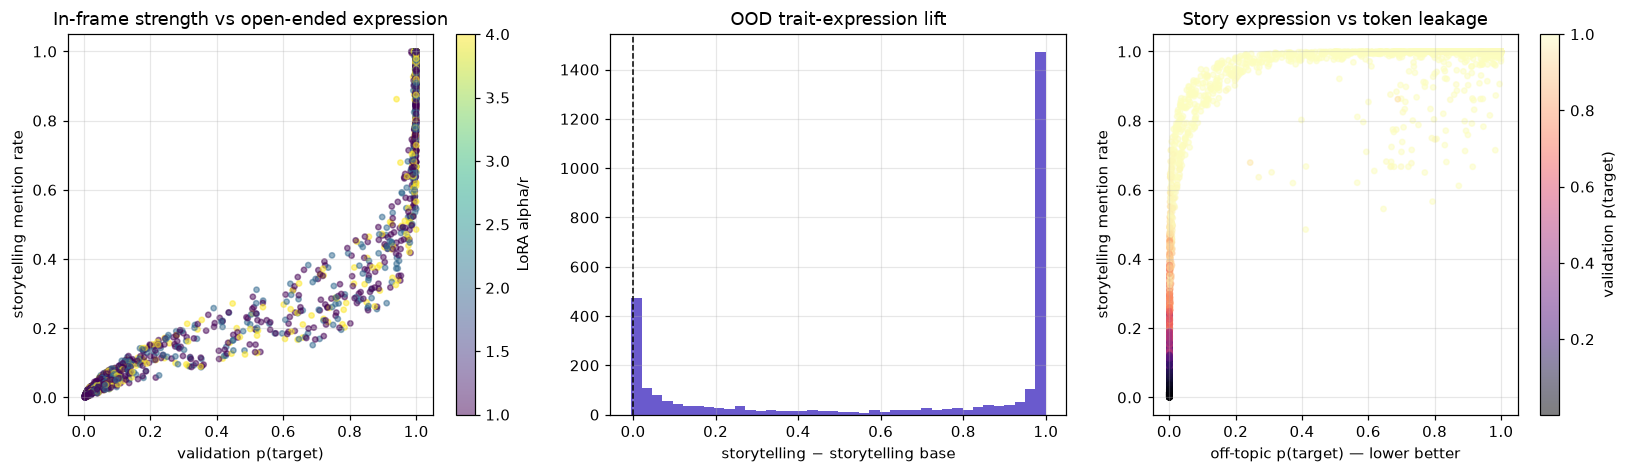

Storytelling rates by animal (configuration-weighted; coverage shown):


,configs,storytelling,base_storytelling,delta,validation
animal,,,,,
lion,576,0.714,0.004,+0.710,0.790
pig,576,0.675,0.001,+0.674,0.763
rabbit,576,0.675,0.002,+0.673,0.763
dog,648,0.648,0.019,+0.628,0.720
cat,720,0.575,0.008,+0.567,0.627


In [16]:
# storytelling_delta now arrives on `wide` from frames.pref_to_wide.
st = wide.dropna(subset=["validation", "storytelling", "base_storytelling"]).copy()
frames.print_scope(st)
print(f"mean storytelling={st.storytelling.mean():.3f} | mean base={st.base_storytelling.mean():.3f} | "
      f"mean Δ={st.storytelling_delta.mean():+.3f}")

fig, ax = plt.subplots(1, 3, figsize=(15, 4.4))
sc = aplots.identity_scatter(ax[0], st, "validation", "storytelling", color_by="lora_alpha_over_r",
                             cmap="viridis", s=12, alpha=.5, stat=None, title_stats=False,
                             diag_lim=None)
ax[0].set_xlabel("validation p(target)")
ax[0].set_ylabel("storytelling mention rate")
ax[0].set_title("In-frame strength vs open-ended expression")
fig.colorbar(sc, ax=ax[0], label="LoRA alpha/r")
ax[1].hist(st["storytelling_delta"], bins=40, color="slateblue")
ax[1].axvline(0, color="black", ls="--", lw=1)
ax[1].set_xlabel("storytelling − storytelling base")
ax[1].set_title("OOD trait-expression lift")

both = st.dropna(subset=["off_topic"])
sc2 = ax[2].scatter(both["off_topic"], both["storytelling"], c=both["validation"],
                    cmap="magma", s=12, alpha=.5)
ax[2].set_xlabel("off-topic p(target) — lower better")
ax[2].set_ylabel("storytelling mention rate")
ax[2].set_title("Story expression vs token leakage")
fig.colorbar(sc2, ax=ax[2], label="validation p(target)")
plt.tight_layout(); plt.show()

story_by_animal = (st.groupby("animal")
    .agg(configs=("param_tag", "size"), storytelling=("storytelling", "mean"),
         base_storytelling=("base_storytelling", "mean"), delta=("storytelling_delta", "mean"),
         validation=("validation", "mean"))
    .sort_values("delta", ascending=False))
print("Storytelling rates by animal (configuration-weighted; coverage shown):")
display(story_by_animal.style.format({
    "storytelling": "{:.3f}", "base_storytelling": "{:.3f}", "delta": "{:+.3f}", "validation": "{:.3f}"}))

## 7. Relative teacher-FT strength across (animal × base-model) — comparable sweeps only ⭐

Naively laying every (animal × base-model) sweep side by side is misleading when the sweeps cover
different amounts of the grid: a thin ~36-config **animal screen** samples a different, smaller HP
region than a full ~288–360-config sweep, so their strength distributions aren't on the same
footing. This section makes the comparison fair with two guards, then reads off relative strength on
*identical* configs.

> **Guard 1 — completeness filter.** Keep only (animal × base-model) sweeps with at least
> `COMPLETENESS_MIN` configs (default 200). This drops the ~36-config animal screens. It does **not**
> penalise a sweep for leaving out an entire axis (e.g. lr 1e-5, or lr 5e-4 past 7 epochs) as long as
> the sweep stayed large — those gaps are absorbed by guard 2.
>
> **Guard 2 — common config set.** Restrict every surviving sweep to the configs they *all* ran (the
> intersection of `param_tag`s). Each grid cell is then the mean validation over the **same** HP cells
> (identical `n`), seeds already pre-averaged upstream — so a difference between two cells is a real
> strength difference, not a coverage artefact.
>
> With the current data this keeps **10 sweeps** (5 animals × {original, data-seed1}, own-sweep size
> 288–360) and drops 54 thinner ones; the common set is **288 configs** (epochs 1–20, lr 1e-4→1e-3,
> all 9 LoRA cells — lr 1e-5 and epoch 40 fall out because not every kept sweep ran them).

The grid is **animals (rows, strongest-first) × base models (cols)**, each cell the HP-averaged mean
validation `p_target` over the common set (the colour scale is zoomed to the data range so the small
differences show). The table underneath adds the distribution detail the mean hides — median, lower
quartile, and the share of the grid that clears 0.5. Tune `COMPLETENESS_MIN` to trade coverage for
comparability; as more animals/models finish their full sweeps they enter this grid automatically.

Comparable sweeps: kept 10 pairings with >= 200 configs (own-sweep size 288–360); dropped 54 thinner sweeps (<= 50 configs — the animal screens, biased to a different HP region).
Common config set = 288 configs run by ALL kept sweeps (epochs [1, 2, 3, 5, 7, 10, 15, 20]; lr ['0.0001', '0.0002', '0.0005', '0.001']; 9 LoRA cells). Every grid cell = mean validation over these identical 288 configs (HP-averaged, seeds pre-averaged).


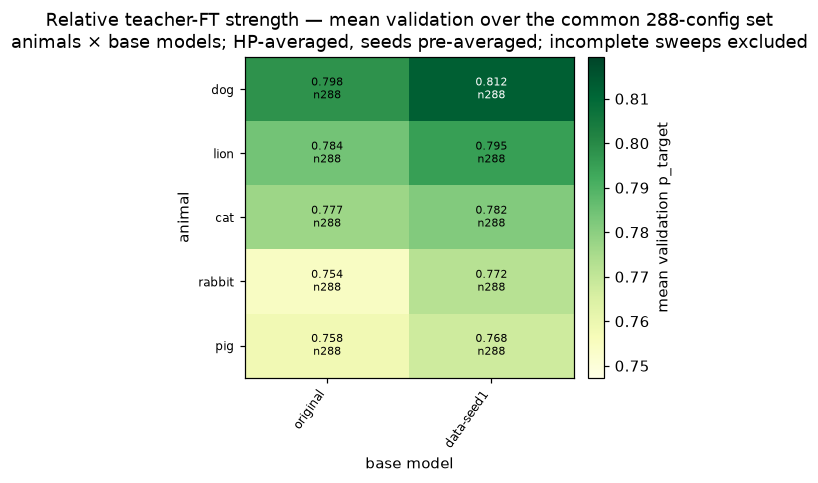


Per (animal × base-model) over the common 288-config set, strongest mean first:


animal,model,n,mean,median,p25,frac>=0.5
dog,data-seed1,288,0.8124,0.9999,0.857,0.81
dog,original,288,0.7977,0.9997,0.781,0.79
lion,data-seed1,288,0.7951,1.0000,0.820,0.79
lion,original,288,0.7840,0.9999,0.750,0.79
cat,data-seed1,288,0.7816,1.0000,0.717,0.79
cat,original,288,0.7771,0.9999,0.712,0.78
rabbit,data-seed1,288,0.7723,1.0000,0.650,0.76
pig,data-seed1,288,0.7676,1.0000,0.622,0.76
pig,original,288,0.7581,1.0000,0.529,0.76
rabbit,original,288,0.7543,0.9999,0.511,0.75


In [17]:
# --- Relative teacher-FT strength across (animal x base-model), on COMPARABLE sweeps only. Two
#     guards make it fair (else a thin 36-config screen differs just from sampling a different HP
#     region): (1) completeness filter -- keep only sweeps with >= COMPLETENESS_MIN configs (drops
#     the ~36-config animal screens; does NOT punish a large sweep for skipping an axis); (2) common
#     config set -- restrict survivors to the configs they ALL ran, so every cell is HP-averaged over
#     the SAME grid (identical n), seeds already pre-averaged. ---
COMPLETENESS_MIN = 200
G = frames.MAIN_GRID
dv = frames.filter_grid(wide.dropna(subset=["validation"]),
                        epochs=G["epochs"], lrs=G["lrs"], ranks=G["ranks"])
cnt = dv.groupby(["animal", "model"]).param_tag.nunique().sort_values(ascending=False)
kept, dropped = cnt[cnt >= COMPLETENESS_MIN], cnt[cnt < COMPLETENESS_MIN]
pairs = list(kept.index)
config_sets = [set(dv[(dv.animal == a) & (dv.model == m)].param_tag) for (a, m) in pairs]
common = set.intersection(*config_sets) if config_sets else set()
keep_idx = dv.set_index(["animal", "model"]).index.isin(pairs)
dvc = dv[keep_idx & dv.param_tag.isin(common)].copy()
dvc["mk"] = dvc.model.map(frames.short_model)

print(f"Comparable sweeps: kept {len(kept)} pairings with >= {COMPLETENESS_MIN} configs "
      f"(own-sweep size {int(kept.min())}–{int(kept.max())}); dropped {len(dropped)} thinner sweeps "
      f"(<= {int(dropped.max())} configs — the animal screens, biased to a different HP region).")
_eps = [int(e) for e in sorted(dvc.n_epochs.unique())]
_lrs = [f"{x:g}" for x in sorted(dvc.learning_rate.unique())]
print(f"Common config set = {len(common)} configs run by ALL kept sweeps "
      f"(epochs {_eps}; lr {_lrs}; 9 LoRA cells). Every grid cell = mean validation over these "
      f"identical {len(common)} configs (HP-averaged, seeds pre-averaged).")

# Grid: animals (rows, strongest-first) x base models (cols); cell = mean validation over common set.
mk_order = [frames.short_model(m) for m in frames.MODEL_ORDER if frames.short_model(m) in set(dvc.mk)]
mean_grid = dvc.pivot_table(index="animal", columns="mk", values="validation", aggfunc="mean")
n_grid = dvc.pivot_table(index="animal", columns="mk", values="validation", aggfunc="size")
arow = mean_grid.mean(axis=1).sort_values(ascending=False).index   # strongest animal first
mean_grid, n_grid = mean_grid.reindex(index=arow, columns=mk_order), n_grid.reindex(index=arow, columns=mk_order)

fig, ax = plt.subplots(figsize=(1.8 + 1.5 * len(mk_order), 1.4 + 0.62 * len(arow)))
lo, hi = mean_grid.min().min(), mean_grid.max().max()
pad = 0.12 * (hi - lo)   # zoom colour scale to the data range so small differences are visible
im = aplots.annotated_heatmap(ax, mean_grid, counts=n_grid, cmap="YlGn",
                              vmin=lo - pad, vmax=hi + pad, fmt="{:.3f}", origin="upper")
fig.colorbar(im, ax=ax, fraction=0.046, pad=0.04, label="mean validation p_target")
ax.set_title(f"Relative teacher-FT strength — mean validation over the common {len(common)}-config "
             f"set\nanimals × base models; HP-averaged, seeds pre-averaged; incomplete sweeps excluded")
ax.set_xlabel("base model"); ax.set_ylabel("animal")
plt.tight_layout(); plt.show()

# Exact numbers, incl. distribution detail the mean hides (median / lower quartile / share >= 0.5).
summ = (dvc.groupby(["animal", "mk"]).validation
        .agg(n="size", mean="mean", median="median",
             p25=lambda s: s.quantile(.25), frac_ge_05=lambda s: (s >= 0.5).mean())
        .reset_index().sort_values("mean", ascending=False)
        .rename(columns={"mk": "model", "frac_ge_05": "frac>=0.5"}))
print(f"\nPer (animal × base-model) over the common {len(common)}-config set, strongest mean first:")
display(summ.style.format({"mean": "{:.4f}", "median": "{:.4f}", "p25": "{:.3f}", "frac>=0.5": "{:.2f}"})
        .background_gradient(cmap="YlGn", subset=["mean"]).hide(axis="index"))


## 8. Trait install vs epochs — (animal × base-model) on the common config set ⭐

§7 collapses each comparable sweep to a single HP-averaged number. This section keeps the **same
fairness guards** (the completeness filter → common config set built in §7) but resolves that number
**across epochs**, so you see not just *which* (animal × base-model) installs the trait more strongly
but *how fast*. At each epoch the mean is over the **36 shared LR × LoRA cells** (seeds pre-averaged),
so every point is an equal-`n`, like-for-like comparison.

> **Reading it.** One line per (animal × base-model): **colour = animal**, **line style = base model**
> (original solid, data-seed1 dashed). Dotted horizontals mark the 0.5 / 0.8 qualifying bars; x is
> log-epochs.
>
> The separation between animals — and between the two base models of the same animal — lives at
> **1–7 epochs**; by 15–20 epochs everything saturates to ~1.0. So the "stronger teacher" differences
> are really differences in **install speed**, not final ceiling. The companion table reports the
> **first epoch each pairing's mean clears 0.5 and 0.8** — the actionable summary of that speed.

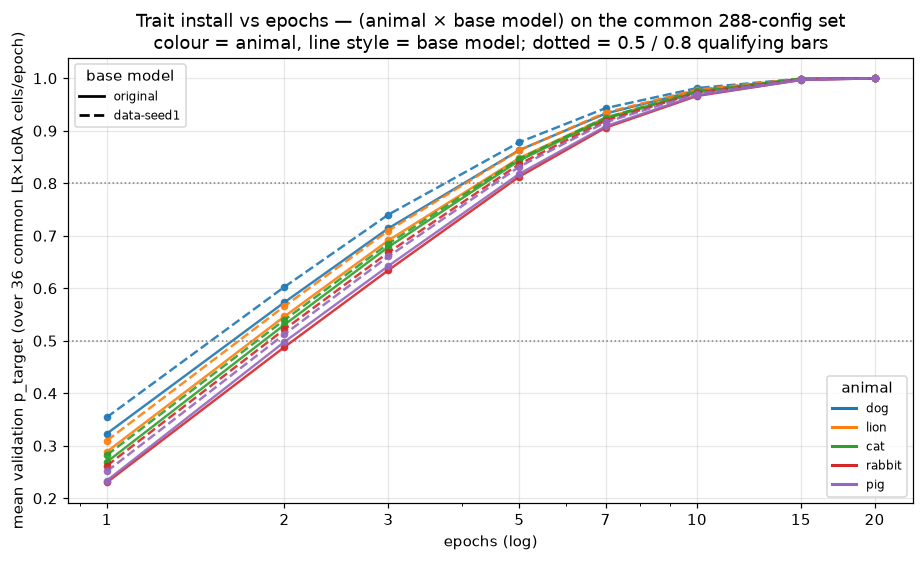

First epoch the epoch-averaged mean clears each bar (fewer epochs = faster install):


animal,base_model,epochs>=0.5,epochs>=0.8,grid_mean
dog,data-seed1,2,5,0.812
dog,original,2,5,0.798
lion,data-seed1,2,5,0.795
lion,original,2,5,0.784
cat,data-seed1,2,5,0.782
cat,original,2,5,0.777
rabbit,data-seed1,2,5,0.772
pig,data-seed1,2,5,0.768
pig,original,3,5,0.758
rabbit,original,3,5,0.754


In [18]:
# Dose-response on the SAME constrained data as §7 (completeness-filtered sweeps restricted to their
# common config set): reuse `dvc` / `common` / `mk_order` from §7. Here we resolve the HP-averaged
# strength ACROSS EPOCHS — at each epoch the mean is over the 36 shared LR×LoRA cells (equal n, seeds
# pre-averaged). Colour = animal, line style = base model.
from matplotlib.lines import Line2D

animals_o = list(dvc.groupby("animal").validation.mean().sort_values(ascending=False).index)
acolors = dict(zip(animals_o, plt.cm.tab10.colors))
STYLES = ["-", "--", ":", "-."]
mstyle = {m: STYLES[i % len(STYLES)] for i, m in enumerate(mk_order)}
curve = dvc.groupby(["animal", "mk", "n_epochs"]).validation.mean().reset_index()
ep_vals = sorted(dvc.n_epochs.unique())

fig, ax = plt.subplots(figsize=(8.5, 5.2))
for a in animals_o:
    for m in mk_order:
        g = curve[(curve.animal == a) & (curve.mk == m)].sort_values("n_epochs")
        if not len(g):
            continue
        ax.plot(g.n_epochs, g.validation, mstyle[m], marker="o", ms=4, lw=1.6,
                color=acolors[a], alpha=0.9)
for y in (0.5, 0.8):
    ax.axhline(y, ls=":", c="grey", lw=1)
ax.set_xscale("log"); ax.set_xticks(ep_vals)
ax.get_xaxis().set_major_formatter(plt.matplotlib.ticker.ScalarFormatter())
ax.set_xlabel("epochs (log)")
ax.set_ylabel(f"mean validation p_target (over {len(common) // len(ep_vals)} common LR×LoRA cells/epoch)")
ax.set_title(f"Trait install vs epochs — (animal × base model) on the common {len(common)}-config set\n"
             "colour = animal, line style = base model; dotted = 0.5 / 0.8 qualifying bars")
leg1 = ax.legend([Line2D([0], [0], color=acolors[a], lw=2) for a in animals_o], animals_o,
                 title="animal", fontsize=8, loc="lower right")
ax.add_artist(leg1)
ax.legend([Line2D([0], [0], color="k", ls=mstyle[m], lw=1.8) for m in mk_order], mk_order,
          title="base model", fontsize=8, loc="upper left")
plt.tight_layout(); plt.show()

# Companion: first epoch each pairing's HP-averaged mean clears 0.5 / 0.8 (the install-speed summary).
def _first_epoch(g, thr):
    q = g[g.validation >= thr]
    return int(q.n_epochs.min()) if len(q) else None

qual = pd.DataFrame(
    [{"animal": a, "base_model": m,
      "epochs>=0.5": _first_epoch(curve[(curve.animal == a) & (curve.mk == m)], 0.5),
      "epochs>=0.8": _first_epoch(curve[(curve.animal == a) & (curve.mk == m)], 0.8),
      "grid_mean": curve[(curve.animal == a) & (curve.mk == m)].validation.mean()}
     for a in animals_o for m in mk_order]).sort_values("grid_mean", ascending=False)
print("First epoch the epoch-averaged mean clears each bar (fewer epochs = faster install):")
display(qual.style.format({"grid_mean": "{:.3f}"}, na_rep="—").hide(axis="index"))


### Takeaways

1. **Base models have faint, ordered latent animal preferences.**
2. **Installation is a joint dose-response in epochs × learning rate × explicit rank/alpha.**
3. **Preference transfers to unseen prompts within the same causal-completion frame.**
4. **Dislike diagnoses valence-blind animal-token upweighting; off-topic separately diagnoses
   unconditional token injection. Both should remain low relative to validation.**
5. **Storytelling is an OOD expression measure, not a simple higher/lower-is-always-better target.**
   Positive lift with low controls supports broad but specific expression; moderate strength may be
   preferable operationally when selecting subtle teachers for distillation.
6. **Trait strength can trade off against number-data quality**, motivating selection from the
   validation/storytelling/control operating space rather than validation alone.
